# DeFi Exploit-Risk Model (v4) — can yield/TVL data rank pools by exploit risk?

A clean, ML-first rebuild of the forensic risk engine. It reuses the **data cache and the leakage-safe ideas** from the feasibility study, but fixes the reasons the ML part produced weak results.

### What the feasibility run (your saved outputs) actually showed

| Finding in `feasibility_v4` | Consequence |
|---|---|
| All 5 folds printed `anomaly-only (3–4 incidents, need 5)` | **The supervised classifier never trained.** The "model" arm was only an Isolation Forest (ROC 0.516). |
| 101 positive rows from 6 incidents; test blocks held 2 / 0 / 3 / 7 / 3 incidents | Walk-forward starves the classifier early and leaves almost nothing to test on. |
| `apy` single-feature AUC 0.23, `tvl_dd_30` 0.29, `tvl_ret_30` 0.28 (i.e. ≈0.77 / 0.71 / 0.72 when inverted) | Pre-hack pools tend to have **lower** APY and **falling** TVL. An unsupervised forest flags *high* outliers — the wrong prior. A supervised model can learn direction. |
| Label purge = 8 days while pool labels look `POST_DAYS` past the event | Small boundary leak. Now purge = `LOOKAHEAD + POST_DAYS`. |

### What v4 changes (ML first, nothing else added)

1. **Primary validation = purged, project-grouped K-fold**, repeated. Every incident is scored by a model that never saw that project, and the classifier trains on ~15+ incidents instead of 3. Strict **walk-forward is kept as a stress test**, not the headline.
2. **Three supervised learners + ensemble** (regularised logistic regression, shallow gradient boosting, extra-trees) trained with incident-balanced weights; Isolation Forest kept only as a comparison.
3. **Market-relative features** (TVL change vs. the day's market, cross-sectional percentiles, project-wide stress) so the model sees "unusual *today*", not just "unusual ever".
4. **Honest baselines**: the best single feature *chosen inside each training fold*. ML must beat that to claim anything.
5. **Two questions answered separately** — *risk profile* (row-level AUC/PR-AUC) and *timing* (does the score rise in the 7 days before a hack, versus the same project's ordinary earlier weeks).
6. **Positive and negative controls** on synthetic data prove the evaluation can find skill when it exists and does not invent it when it doesn't.

The vault / keeper / replay layer from v2–v3 is intentionally **not** in this notebook; it was never the bottleneck.

### Pre-specified decision rule (frozen before any real-data result)
* **A – risk profile:** ensemble row-level ROC-AUC CI lower bound > 0.5 **and** PR-AUC CI lower bound > base rate.
* **B – timing:** mean within-project placebo percentile of the pre-hack window has CI lower bound > 0.5 (one-sided Wilcoxon p < 0.05).
* Verdict: **A and B → skill**; **A only → risk-profile only (ranks which pools get hit, not when)**; otherwise **no evidence**.
* The ML-vs-best-single-feature gap is reported with a CI, never hidden.

## 1. Configuration

In [1]:
from __future__ import annotations
import hashlib, json, os, platform, re, sys, time, warnings
from collections import defaultdict
from dataclasses import dataclass, replace, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from scipy.stats import wilcoxon
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer

try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)


@dataclass
class Config:
    # ---- data ----
    DATA_SOURCE: str = os.environ.get("DEFI_DATA_SOURCE", "real")   # "real" = DeFiLlama cache in artifacts/raw | "synthetic" = smoke test ONLY
    ALLOW_NETWORK: bool = False       # True only to (re)populate artifacts/raw; then set back to False
    ARTIFACT_DIR: str = "artifacts"
    MAX_POOLS: int = 600
    MIN_TVL_FETCH: float = 1_000_000
    EXTRA_HACKED_POOLS: int = 150
    REQUEST_DELAY: float = 0.25
    MAX_REQUESTS: int = 900
    MIN_HISTORY_DAYS: int = 45
    APY_SANITY_MAX: float = 10_000.0
    SEED: int = 42
    # ---- synthetic universe (controls / smoke test only) ----
    SYN_PROJECTS: int = 60
    SYN_DAYS: int = 720
    SYN_INCIDENTS: int = 24
    SYN_PRECURSOR: float = 1.0        # 1 = planted precursor, 0 = NO precursor (negative control)
    # ---- features ----
    DROP_ZERO_APY: bool = True
    STABLE_MIN_AGE: int = 60
    STABLE_MIN_TVL: float = 1_000_000
    MIN_POOLS_PER_DAY: int = 30
    # ---- labels ----
    LOOKAHEAD_DAYS: int = 7           # alert horizon: positives are the L days before the event
    LABEL_GAP_DAYS: int = 0           # >0 drops the last days before the event (robustness vs. imprecise hack dates)
    COOLDOWN_DAYS: int = 30
    POST_DAYS: int = 14               # victim-pool window after the event
    POOL_IMPACT_MIN: float = 0.10     # pool TVL must fall >= this within POST_DAYS to count as a victim pool
    EXCLUDE_TECHNIQUE_REGEX: str = (r"phish|private.?key|key.?compromis|compromised.?key|leaked|social.?engineer|"
                                    r"dns|domain|front.?end|spoof|supply.?chain|malware|credential|insider|seed.?phrase")
    EXCLUDE_CLASSIFICATIONS: tuple = ("infrastructure", "cefi")
    INCLUDE_UNCLASSIFIED: bool = False
    ACCEPT_CORE_NAME_MATCH: bool = True   # unique "same core name + project has history before the hack" matches; always listed for review
    # ---- validation ----
    CV_FOLDS: int = 5
    CV_REPEATS: int = 2
    EMBARGO_PRE: int = 14             # train rows of OTHER projects within [event-PRE, event+POST] of a test incident are dropped
    EMBARGO_POST: int = 30
    WF_FOLDS: int = 3
    WF_MIN_TRAIN_DAYS: int = 365
    # ---- models ----
    NEG_CAP: int = 80_000             # negatives sub-sampled to this many rows (inverse-rate weights)
    INCIDENT_WEIGHT_FRAC: float = 0.02  # each incident's positive rows carry this share of total negative weight
    MIN_TRAIN_INCIDENTS: int = 3
    # ---- evaluation ----
    ALPHA: float = 0.05
    BOOT: int = 200                   # project-cluster bootstrap draws (row level)
    BOOT_INC: int = 5000              # incident bootstrap draws
    ALERT_BUDGETS: tuple = (0.01, 0.02, 0.05)
    MIN_PLACEBO_WINDOWS: int = 20
    PLACEBO_LOOKBACK_DAYS: int = 180  # placebo windows come only from this many days of the project's OWN history before the pre-hack window
    RUN_ABLATIONS: bool = True
    RUN_WALK_FORWARD: bool = True
    RUN_GAP_CHECK: bool = True
    RUN_CONTROLS: bool = True

    @property
    def PURGE_DAYS(self) -> int:      # labels of a training row depend on data up to event + POST_DAYS
        return self.LOOKAHEAD_DAYS + self.LABEL_GAP_DAYS + self.POST_DAYS


CFG = Config()
OUT = Path(CFG.ARTIFACT_DIR) / "v4"; OUT.mkdir(parents=True, exist_ok=True)
ALIASES: dict = {}     # human-reviewed {hack-feed name: pool project slug}; empty by default

# Feature groups. Pool size (log TVL) is deliberately absent: it is a selection proxy (hacked projects were force-included).
GROUPS = {
    "pool_tvl":   ["tvl_ret_1", "tvl_ret_7", "tvl_ret_30", "tvl_dd_30", "tvl_vol_7"],
    "pool_apy":   ["apy", "apy_delta_7", "apy_vol_7", "apy_z_30", "apy_ratio_30", "reward_share", "apy_xs_stable"],
    "protocol":   ["proto_tvl_ret_7", "proto_tvl_dd_30", "proj_frac_falling"],
    "market_rel": ["mkt_tvl_ret_7", "tvl_ret_7_rel", "tvl_ret_7_xs", "tvl_dd_30_xs"],
}
FEATURES = [f for g in GROUPS.values() for f in g]
LEARNERS = ("logreg", "hgb", "extra")
print(f"DATA_SOURCE={CFG.DATA_SOURCE}  ALLOW_NETWORK={CFG.ALLOW_NETWORK}  features={len(FEATURES)}  purge={CFG.PURGE_DAYS}d")
if CFG.DATA_SOURCE != "real":
    print("*** NOT REAL DATA — results from this run say nothing about real exploits ***")

DATA_SOURCE=real  ALLOW_NETWORK=False  features=19  purge=21d


## 2. Data layer
* **Real:** reads the DeFiLlama cache you already built (`artifacts/raw/…`, same layout as the feasibility notebook, so nothing is re-downloaded). `fetch_cache` only runs if `ALLOW_NETWORK=True` and a file is missing.
* **Synthetic:** a small planted-precursor universe used **only** for the positive/negative controls and smoke tests.

In [2]:
HEADERS = {"User-Agent": "defi-exploit-risk/4.0"}


def parse_dates(values: pd.Series) -> pd.Series:
    if pd.api.types.is_datetime64_any_dtype(values):
        return pd.to_datetime(values, utc=True)
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().mean() > 0.8:
        unit = "ms" if numeric.dropna().abs().median() > 1e12 else "s"
        return pd.to_datetime(numeric, unit=unit, utc=True, errors="coerce")
    return pd.to_datetime(values, utc=True, errors="coerce")


def to_day_num(ts: pd.Series) -> np.ndarray:
    """tz-aware timestamps -> integer days since epoch (UTC)."""
    return ts.dt.tz_convert("UTC").dt.tz_localize(None).values.astype("datetime64[D]").astype("int64")


def normalize_name(s) -> str:
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


GENERIC = {"finance", "protocol", "network", "dao", "labs", "swap", "exchange", "fi", "money", "capital", "token", "bridge", "chain", "v1", "v2", "v3"}


def core_name(s) -> str:
    toks = [t for t in re.split(r"[^a-z0-9]+", str(s).lower()) if t]
    return "".join(t for t in toks if t not in GENERIC) or normalize_name(s)


class BudgetExceeded(RuntimeError):
    pass


def fetch_cache(cfg: Config):
    """Populate artifacts/raw from DeFiLlama. Cache-first, resumable, hard request cap. Only runs when ALLOW_NETWORK=True."""
    import requests
    from urllib.parse import quote
    raw = Path(cfg.ARTIFACT_DIR) / "raw"; (raw / "charts").mkdir(parents=True, exist_ok=True)
    n_live = 0

    def get(url, path):
        nonlocal n_live
        if path.exists():
            return json.loads(path.read_text(encoding="utf-8"))
        if not cfg.ALLOW_NETWORK:
            raise RuntimeError(f"Cache miss for '{path.name}' and ALLOW_NETWORK is False. Set it True once to populate the cache.")
        if n_live >= cfg.MAX_REQUESTS:
            raise BudgetExceeded(f"MAX_REQUESTS={cfg.MAX_REQUESTS} reached; cache kept, rerun to resume.")
        for attempt in range(3):
            try:
                r = requests.get(url, headers=HEADERS, timeout=30); r.raise_for_status(); data = r.json(); break
            except (requests.RequestException, ValueError):
                if attempt == 2: raise
                time.sleep(2 ** attempt)
        n_live += 1; path.write_text(json.dumps(data), encoding="utf-8"); time.sleep(cfg.REQUEST_DELAY)
        return data

    hacks = get("https://api.llama.fi/hacks", raw / "hacks.json")
    hacks = hacks.get("data", hacks) if isinstance(hacks, dict) else hacks
    protocols = get("https://api.llama.fi/protocols", raw / "protocols.json")
    protocols = protocols.get("protocols", protocols) if isinstance(protocols, dict) else protocols
    id_to_slugs = defaultdict(set)
    for p in protocols:
        if isinstance(p, dict) and p.get("slug"):
            id_to_slugs[str(p.get("id"))].add(p["slug"])
            if p.get("parentProtocol"): id_to_slugs[str(p["parentProtocol"])].add(p["slug"])
    cat = get("https://yields.llama.fi/pools", raw / "pool_catalog.json")
    pools = pd.DataFrame(cat.get("data", cat) if isinstance(cat, dict) else cat)
    pools["tvlUsd"] = pd.to_numeric(pools["tvlUsd"], errors="coerce")
    pools = pools.dropna(subset=["pool", "project"]).drop_duplicates("pool")
    sel = (pools.dropna(subset=["tvlUsd"]).loc[lambda f: f.tvlUsd >= cfg.MIN_TVL_FETCH]
           .sort_values("tvlUsd", ascending=False).head(cfg.MAX_POOLS))
    # Hacked projects are often drained/delisted, so a plain top-N-by-TVL universe contains almost no victims -> force-include them.
    hinted = {s for h in hacks for k in [h.get("defillamaId")] if k not in (None, "") for s in id_to_slugs.get(str(k), [])}
    named = {normalize_name(h.get("name", "")) for h in hacks} - {""}
    mine = pools[pools.project.isin(hinted) | pools.project.map(normalize_name).isin(named)]
    sel = pd.concat([sel, mine.sort_values("tvlUsd", ascending=False).head(cfg.EXTRA_HACKED_POOLS)]).drop_duplicates("pool")
    for r in sel.itertuples(index=False):
        try:
            get(f"https://yields.llama.fi/chart/{quote(str(r.pool), safe='')}", raw / "charts" / f"{r.pool}.json")
        except BudgetExceeded as e:
            print("WARNING - PARTIAL CACHE:", e); break
        except requests.RequestException:
            continue
    print(f"fetch_cache: live requests={n_live}, charts on disk={len(list((raw / 'charts').glob('*.json')))}")


def load_cache(cfg: Config):
    """Read artifacts/raw -> (history DataFrame, hack feed list). Hacks are tied to pool projects through DeFiLlama ids."""
    raw = Path(cfg.ARTIFACT_DIR) / "raw"
    if not (raw / "pool_catalog.json").exists() or not (raw / "hacks.json").exists():
        if cfg.ALLOW_NETWORK: fetch_cache(cfg)
        else: raise FileNotFoundError(f"No cache at {raw.resolve()}. Copy your existing artifacts/raw here, or set ALLOW_NETWORK=True once.")
    rd = lambda p: json.loads((raw / p).read_text(encoding="utf-8"))
    hacks = rd("hacks.json"); hacks = hacks.get("data", hacks) if isinstance(hacks, dict) else hacks
    protocols = rd("protocols.json"); protocols = protocols.get("protocols", protocols) if isinstance(protocols, dict) else protocols
    id_to_slugs = defaultdict(set)
    for p in protocols:
        if isinstance(p, dict) and p.get("slug"):
            id_to_slugs[str(p.get("id"))].add(p["slug"])
            if p.get("parentProtocol"): id_to_slugs[str(p["parentProtocol"])].add(p["slug"])
    for h in hacks:
        k = h.get("defillamaId")
        h["projects_hint"] = sorted(id_to_slugs.get(str(k), [])) if k not in (None, "") else []
    cat = rd("pool_catalog.json"); cat = pd.DataFrame(cat.get("data", cat) if isinstance(cat, dict) else cat).drop_duplicates("pool")
    info = cat.set_index("pool")[["project", "symbol"]].astype(str).to_dict("index")
    rows, n_missing = [], 0
    for fp in sorted((raw / "charts").glob("*.json")):
        pool = fp.stem
        if pool not in info: n_missing += 1; continue
        payload = json.loads(fp.read_text(encoding="utf-8")); obs = payload.get("data", payload) if isinstance(payload, dict) else payload
        pr, sy = info[pool]["project"], info[pool]["symbol"]
        rows += [(pool, pr, sy, o.get("timestamp"), o.get("tvlUsd"), o.get("apy"), o.get("apyBase"), o.get("apyReward")) for o in obs if isinstance(o, dict)]
    hist = pd.DataFrame(rows, columns=["pool", "project", "symbol", "timestamp", "tvlUsd", "apy", "apyBase", "apyReward"])
    print(f"cache: {hist.pool.nunique()} pools, {len(hacks)} hack-feed events, chart files without catalogue entry: {n_missing}")
    return hist, hacks


def make_synthetic(cfg: Config):
    """Planted-precursor universe in DeFiLlama shape. Ground truth lives only here. Used for controls / smoke tests."""
    rng = np.random.default_rng(cfg.SEED)
    T, NP, L = cfg.SYN_DAYS, cfg.SYN_PROJECTS, cfg.LOOKAHEAD_DAYS
    days = pd.date_range("2024-01-01", periods=T, freq="D", tz="UTC")
    symbols = np.array(["USDC", "USDT", "DAI", "WETH", "WBTC", "stETH"])
    projects = [f"proto-{i:02d}" for i in range(NP)]
    ev_days = np.clip(np.linspace(60, T - 30, cfg.SYN_INCIDENTS).astype(int) + rng.integers(-4, 5, cfg.SYN_INCIDENTS), 40, T - 25)
    ev_projects = rng.choice(projects, size=cfg.SYN_INCIDENTS, replace=False)
    spec = {}
    for p, d in zip(ev_projects, ev_days):
        has_precursor, strength = rng.random() < 0.7, float(rng.uniform(0.6, 1.5))
        spec[p] = dict(day=int(d), strength=strength * cfg.SYN_PRECURSOR if has_precursor else 0.0,
                       mode=str(rng.choice(["hype", "bleed"])), drop=float(rng.uniform(0.5, 0.9)))
    t_idx, recs, pools_meta = np.arange(T), [], []
    for p in projects:
        s = spec.get(p); proj_walk = np.cumsum(rng.normal(0, 0.02, T)); proj_mult, apy_mult = np.ones(T), np.ones(T)
        if s:
            d = s["day"]; ramp = np.clip((t_idx - (d - L)) / L, 0, 1) * (t_idx < d)
            apy_mult = 1 + 1.2 * s["strength"] * ramp
            proj_mult = (1 + 0.10 * s["strength"] * ramp) if s["mode"] == "hype" else (1 - 0.12 * s["strength"] * ramp)
            proj_mult = np.where(t_idx >= d, proj_mult * (1 - s["drop"]), proj_mult); apy_mult = np.where(t_idx >= d, 0.3, apy_mult)
        base_tvl, reward_share = rng.lognormal(18.0, 1.0), rng.uniform(0.0, 0.7)
        for k in range(int(rng.integers(2, 6))):
            tvl = base_tvl * rng.uniform(0.15, 1.0) * np.exp(proj_walk + np.cumsum(rng.normal(0, 0.01, T))) * proj_mult
            mu = rng.lognormal(1.5, 0.6); noise = rng.normal(0, 0.15 * mu + 0.1, T); x = np.empty(T); x[0] = mu
            for t in range(1, T): x[t] = x[t - 1] + 0.08 * (mu - x[t - 1]) + noise[t]
            x = np.clip(x, 0.05, None)
            if (not s) and rng.random() < 0.3:                      # benign spike (false-positive trap)
                b = int(rng.integers(40, T - 5)); x[b:b + 3] *= 2.5
            x = x * apy_mult; name = f"{p}-pool{k}"
            ts = days.tz_convert(None).values
            recs.append(pd.DataFrame(dict(pool=name, project=p, symbol=str(rng.choice(symbols)), timestamp=pd.to_datetime(ts, utc=True),
                                          tvlUsd=tvl, apy=x, apyReward=x * reward_share)))
    hist = pd.concat(recs, ignore_index=True); hist["apyBase"] = hist.apy - hist.apyReward
    hist = hist.loc[rng.random(len(hist)) > 0.02].reset_index(drop=True)
    hacks = [dict(name=p.replace("-", " ").title(), date=int(days[sp["day"]].timestamp()), amount=float(sp["drop"] * 1e7),
                  chain="Ethereum", classification="Protocol Logic", technique="Logic Error") for p, sp in spec.items()]
    hacks += [dict(name=f"Unlisted Protocol {j}", date=int(days[int(rng.integers(0, T))].timestamp()), amount=1e6, chain="BSC") for j in range(25)]
    return hist, hacks


def clean_history(h: pd.DataFrame, cfg: Config):
    rep = {"rows_in": len(h)}; h = h.copy()
    h["timestamp"] = parse_dates(h["timestamp"])
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        h[c] = pd.to_numeric(h[c], errors="coerce") if c in h else np.nan
    bad = h.timestamp.isna() | ~(h.tvlUsd > 0) | h.apy.isna() | ~(h.apy >= 0) | (h.apy > cfg.APY_SANITY_MAX)
    rep["dropped_invalid"] = int(bad.sum()); h = h[~bad].copy()
    h["_day"] = to_day_num(h["timestamp"]); n0 = len(h)
    h = h.sort_values(["pool", "timestamp"]).drop_duplicates(["pool", "_day"], keep="last")
    rep["dropped_duplicate_days"] = n0 - len(h)
    short = h.groupby("pool")["_day"].transform("nunique") < cfg.MIN_HISTORY_DAYS
    rep["dropped_short_history_pools"] = int(h.loc[short, "pool"].nunique()); h = h[~short]; rep["rows_out"] = len(h)
    return h.drop(columns="_day").reset_index(drop=True), rep


def load_universe(cfg: Config):
    if cfg.DATA_SOURCE == "synthetic":
        return make_synthetic(cfg)
    if cfg.DATA_SOURCE == "real":
        return load_cache(cfg)
    raise ValueError("DATA_SOURCE must be 'real' or 'synthetic'")


hist, hacks = load_universe(CFG)
hist, clean_report = clean_history(hist, CFG)
print(f"history rows={len(hist):,}  pools={hist.pool.nunique()}  projects={hist.project.nunique()}  hack-feed events={len(hacks)}")
print("cleaning report:", clean_report)

cache: 600 pools, 1328 hack-feed events, chart files without catalogue entry: 0
history rows=305,794  pools=547  projects=162  hack-feed events=1328
cleaning report: {'rows_in': 306829, 'dropped_invalid': 68, 'dropped_duplicate_days': 136, 'dropped_short_history_pools': 53, 'rows_out': 305794}


## 3. Features (point-in-time)
Every value at day *t* uses only data ≤ *t* (verified by a truncation test in §14). Compared with the feasibility notebook:
* added **`tvl_vol_7`** (TVL instability);
* added **market-relative** features — `mkt_tvl_ret_7` (median pool that day), `tvl_ret_7_rel` (pool minus market), `tvl_ret_7_xs` / `tvl_dd_30_xs` (same-day percentiles) — so a market-wide sell-off no longer looks like a pool-specific warning;
* added **`proj_frac_falling`**: share of the project's pools that fell >10% in 7 days (project-wide stress).

In [3]:
def _mid_rank_pct(ref_sorted: np.ndarray, x: np.ndarray) -> np.ndarray:
    return (np.searchsorted(ref_sorted, x, "left") + np.searchsorted(ref_sorted, x, "right")) / (2 * len(ref_sorted))


def stable_universe_pct(df: pd.DataFrame, cfg: Config) -> np.ndarray:
    """Same-day mid-rank percentile of APY against a stable reference set (age, TVL, APY>0). Uses only that day's rows."""
    age = (df["day_num"] - df.groupby("pool")["day_num"].transform("min")).to_numpy()
    apy, tvl = df["apy"].to_numpy(float), df["tvlUsd"].to_numpy(float)
    stable = (age >= cfg.STABLE_MIN_AGE) & (tvl >= cfg.STABLE_MIN_TVL) & (apy > 0)
    out = np.full(len(df), 0.5)
    for _, idx in df.groupby("day_num").indices.items():
        ref = np.sort(apy[idx][stable[idx]])
        if len(ref) >= 10: out[idx] = _mid_rank_pct(ref, apy[idx])
    return out


def build_features(history: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    df = history.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.floor("D")
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        df[c] = pd.to_numeric(df[c], errors="coerce") if c in df else np.nan
    df = df.dropna(subset=["tvlUsd", "apy"]); df = df[(df.tvlUsd > 0) & (df.apy >= 0)]
    df["apyReward"] = df["apyReward"].fillna(0.0).clip(lower=0)
    df["day_num"] = to_day_num(df["timestamp"])
    df = df.sort_values(["pool", "day_num"]).drop_duplicates(["pool", "day_num"], keep="last").reset_index(drop=True)
    # Dense daily grid per pool (row-based lags are only calendar-correct if every day has a row). Gaps <=3d are forward-filled
    # (past values only); longer gaps stay NaN. Every pool is carried to the global last day so the row set never depends on a pool's future.
    span = df.groupby("pool", sort=False)["day_num"].agg(["min", "max"]); span["max"] = int(df["day_num"].max())
    grid = pd.DataFrame({"pool": np.repeat(span.index.values, (span["max"] - span["min"] + 1).values),
                         "day_num": np.concatenate([np.arange(a, b + 1) for a, b in zip(span["min"], span["max"])])})
    const = df.drop_duplicates("pool")[["pool", "project", "symbol"]]
    df = grid.merge(df[["pool", "day_num", "tvlUsd", "apy", "apyReward"]], on=["pool", "day_num"], how="left").merge(const, on="pool", how="left")
    vcols = ["tvlUsd", "apy", "apyReward"]
    df[vcols] = df.groupby("pool", sort=False)[vcols].ffill(limit=3)
    df["timestamp"] = pd.to_datetime(df["day_num"], unit="D", utc=True)

    df["_apy_lag"] = df.groupby("pool", sort=False)["apy"].shift(1)
    df["_lr"] = np.log(df["tvlUsd"]).groupby(df["pool"], sort=False).diff()
    g = df.groupby("pool", sort=False)

    def roll(col, w, fn, mp):
        return getattr(g[col].rolling(w, min_periods=mp), fn)().reset_index(level=0, drop=True)

    for k in (1, 7, 30):
        df[f"tvl_ret_{k}"] = g["tvlUsd"].pct_change(k, fill_method=None).clip(-1, 10)
    df["tvl_dd_30"] = df["tvlUsd"] / roll("tvlUsd", 30, "max", 5) - 1
    df["tvl_vol_7"] = roll("_lr", 7, "std", 4)
    m30, s30 = roll("_apy_lag", 30, "mean", 10), roll("_apy_lag", 30, "std", 10)
    df["apy_z_30"] = ((df["apy"] - m30) / (s30 + 1e-6)).clip(-10, 10)
    df["apy_ratio_30"] = (df["apy"] / (m30 + 1e-6)).clip(0, 20)
    df["apy_delta_7"] = g["apy"].diff(7)
    df["apy_vol_7"] = roll("apy", 7, "std", 3)
    df["reward_share"] = (df["apyReward"] / (df["apy"] + 1e-6)).clip(0, 1)
    df["apy_xs_stable"] = stable_universe_pct(df, cfg)

    # protocol-level TVL: like-for-like 7d change (only pools observed on BOTH dates, so listings/delistings are not fake collapses)
    wide = df.pivot(index="day_num", columns="pool", values="tvlUsd").sort_index()
    wide = wide.reindex(range(int(wide.index.min()), int(wide.index.max()) + 1)).ffill(limit=3); wide.index.name = "day_num"
    proj_of = df.drop_duplicates("pool").set_index("pool")["project"].reindex(wide.columns)
    proto = wide.T.groupby(proj_of.values).sum(min_count=1).T
    codes, uniq = pd.factorize(proj_of.values)
    W = wide.to_numpy(float); Wp = np.vstack([np.full((7, W.shape[1]), np.nan), W[:-7]])
    both = ~np.isnan(W) & ~np.isnan(Wp)
    M = np.zeros((W.shape[1], len(uniq))); M[np.arange(W.shape[1]), codes] = 1.0
    num, den = np.where(both, W, 0.0) @ M, np.where(both, Wp, 0.0) @ M
    ret7 = pd.DataFrame(np.where(den > 0, num / np.where(den > 0, den, 1.0) - 1, np.nan), index=wide.index, columns=uniq).clip(-1, 10)
    dd30 = proto / proto.rolling(30, min_periods=5).max() - 1
    long = (ret7.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_ret_7")
            .merge(dd30.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_dd_30"), on=["day_num", "project"]))
    df = df.merge(long, on=["day_num", "project"], how="left")
    df = df.drop(columns=["_apy_lag", "_lr"]).replace([np.inf, -np.inf], np.nan)
    if cfg.DROP_ZERO_APY:
        df = df[df["apy"] > 0]
    # market-relative / cross-sectional features (computed on the model universe, same-day information only)
    gd = df.groupby("day_num")
    df["mkt_tvl_ret_7"] = gd["tvl_ret_7"].transform("median")
    df["tvl_ret_7_rel"] = df["tvl_ret_7"] - df["mkt_tvl_ret_7"]
    df["tvl_ret_7_xs"] = gd["tvl_ret_7"].rank(pct=True)
    df["tvl_dd_30_xs"] = gd["tvl_dd_30"].rank(pct=True)
    df["_fall"] = (df["tvl_ret_7"] < -0.10).astype(float).where(df["tvl_ret_7"].notna())
    df["proj_frac_falling"] = df.groupby(["project", "day_num"])["_fall"].transform("mean")
    df = df.drop(columns="_fall").dropna(subset=FEATURES)
    return df.sort_values(["pool", "day_num"]).reset_index(drop=True)


def prepare_features(history: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    f = build_features(history, cfg)
    return f[f.groupby("day_num")["pool"].transform("nunique") >= cfg.MIN_POOLS_PER_DAY].reset_index(drop=True)


feat = prepare_features(hist, CFG)
d0, d1 = int(feat.day_num.min()), int(feat.day_num.max())
print(f"feature rows={len(feat):,}  pools={feat.pool.nunique()}  projects={feat.project.nunique()}  "
      f"{pd.to_datetime(d0, unit='D').date()} -> {pd.to_datetime(d1, unit='D').date()}")

feature rows=217,465  pools=426  projects=151  2022-09-07 -> 2026-10-29


## 4. Incidents and labels
* Hacks are tied to pool projects through DeFiLlama ids (→ slug / parent family), then reviewed aliases, then normalised exact name, then (new) a **unique core-name match where the project already has ≥30 days of history before the hack**. Every match and its method is saved to `incidents_matched.csv` for human review.
* **Only categories that can leave a yield/TVL trace** are positives (key compromise, phishing, DNS/front-end, … are excluded by regex).
* **Pool-level label:** a pool is positive in the `LOOKAHEAD_DAYS` before an event only if its own TVL then fell ≥ `POOL_IMPACT_MIN` within `POST_DAYS` (or the pool vanished). Unaffected pools, non-detectable and immature incidents are **quarantined** — never counted as negatives.

In [4]:
def categorize(classification, technique, cfg: Config):
    cls, tech = str(classification or "").strip(), str(technique or "").strip()
    if re.search(cfg.EXCLUDE_TECHNIQUE_REGEX, f"{tech} {cls}".lower()):
        return False, "technique not observable in yield/TVL data"
    if any(c in cls.lower() for c in cfg.EXCLUDE_CLASSIFICATIONS):
        return False, "classification: " + cls
    if not cls and not tech:
        return bool(cfg.INCLUDE_UNCLASSIFIED), ("" if cfg.INCLUDE_UNCLASSIFIED else "unclassified")
    return True, ""


def match_incidents(hack_feed, feat: pd.DataFrame, cfg: Config, aliases: dict | None = None) -> pd.DataFrame:
    aliases = ALIASES if aliases is None else aliases
    ev = pd.DataFrame(hack_feed)
    name_col = next(c for c in ("name", "protocol", "project") if c in ev.columns)
    date_col = next(c for c in ("date", "timestamp", "time") if c in ev.columns)
    ev["event_name"] = ev[name_col].astype(str); ev["event_time"] = parse_dates(ev[date_col])
    ev = ev.dropna(subset=["event_time"]).reset_index(drop=True); ev["event_day"] = to_day_num(ev["event_time"])
    for c in ("classification", "technique"):
        ev[c] = ev[c].where(ev[c].notna(), "").astype(str) if c in ev.columns else ""
    ev["amount"] = pd.to_numeric(ev["amount"], errors="coerce") if "amount" in ev.columns else np.nan
    projects = list(feat.project.unique()); pset = set(projects)
    span = feat.groupby("project").day_num.agg(["min", "max"])
    proj_norm = {normalize_name(p): p for p in projects}; alias_norm = {normalize_name(k): v for k, v in aliases.items()}
    core_to_proj = defaultdict(list)
    for p in projects: core_to_proj[core_name(p)].append(p)
    hints = ev["projects_hint"] if "projects_hint" in ev.columns else pd.Series([[]] * len(ev))
    rows = []
    for i, (n, day) in enumerate(zip(ev.event_name, ev.event_day)):
        k = normalize_name(n); h = hints.iloc[i]; h = [p for p in h if p in pset] if isinstance(h, list) else []
        if k in alias_norm:   rows.append((i, alias_norm[k], "reviewed alias"))
        elif h:               rows += [(i, p, "defillama id") for p in h]
        elif k in proj_norm:  rows.append((i, proj_norm[k], "normalized exact name"))
        elif cfg.ACCEPT_CORE_NAME_MATCH:
            cand = [p for p in core_to_proj.get(core_name(n), []) if span.at[p, "min"] <= day - 30 and span.at[p, "max"] >= day]
            rows.append((i, cand[0], "core name + history") if len(cand) == 1 else (i, None, ""))
        else:                 rows.append((i, None, ""))
    ev = ev.iloc[[r[0] for r in rows]].reset_index(drop=True)
    ev["project"], ev["match_method"] = [r[1] for r in rows], [r[2] for r in rows]
    in_range = ev.event_day.between(int(feat.day_num.min()), int(feat.day_num.max()))
    m = ev[ev.project.notna() & in_range].drop_duplicates(["project", "event_day"]).copy()
    m["event_id"] = m.project + "|" + m.event_day.astype(str)
    cat = [categorize(a, b, cfg) for a, b in zip(m.classification, m.technique)]
    m["detectable"], m["exclusion_reason"] = [c[0] for c in cat], [c[1] for c in cat]
    cols = ["project", "event_name", "event_time", "event_day", "event_id", "match_method", "classification", "technique", "amount", "detectable", "exclusion_reason"]
    return m[cols].reset_index(drop=True)


def label_rows(feat: pd.DataFrame, incidents: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    out = feat.copy(); d, proj = out.day_num.values, out.project.values
    L, G, C, P = cfg.LOOKAHEAD_DAYS, cfg.LABEL_GAP_DAYS, cfg.COOLDOWN_DAYS, cfg.POST_DAYS
    day_max = int(d.max())
    label = np.zeros(len(out), np.int8); inc = np.full(len(out), "", dtype=object); quar = np.zeros(len(out), bool)
    for r in incidents.itertuples(index=False):
        m = proj == r.project
        pre = m & (d >= r.event_day - L - G) & (d < r.event_day - G)
        quar |= m & (d >= r.event_day - G) & (d < r.event_day + C)          # gap days + event + cooldown
        if not (bool(r.detectable) and r.event_day + P <= day_max):         # not observable / not mature: ambiguous, never a negative
            quar |= pre; continue
        sub = out.loc[m, ["pool", "day_num", "tvlUsd"]]
        pre_t = sub[sub.day_num < r.event_day].groupby("pool").tvlUsd.last()
        post_min = sub[(sub.day_num >= r.event_day) & (sub.day_num <= r.event_day + P)].groupby("pool").tvlUsd.min()
        drop = 1 - post_min.reindex(pre_t.index) / pre_t
        hit = set(drop.index[(drop >= cfg.POOL_IMPACT_MIN) | drop.isna()])    # NaN = pool vanished after the event
        impacted = out.pool.isin(hit).values
        label[pre & impacted] = 1; inc[pre & impacted] = r.event_id
        quar |= pre & ~impacted
    label[quar] = 0; inc[label == 0] = ""
    out["label"], out["incident_id"], out["quarantine"] = label, inc, quar
    return out


def audit_labels(feat, incidents, hacks, cfg):
    d0, d1 = int(feat.day_num.min()), int(feat.day_num.max())
    print(f"universe: {feat.pool.nunique()} pools / {feat.project.nunique()} projects | {pd.to_datetime(d0, unit='D').date()} -> {pd.to_datetime(d1, unit='D').date()}")
    print(f"hack feed={len(hacks)} | matched in range={len(incidents)} {incidents.match_method.value_counts().to_dict()} | detectable={int(incidents.detectable.sum())}")
    print("excluded (not yield-observable):", incidents.loc[~incidents.detectable, "exclusion_reason"].value_counts().to_dict())
    rows = []
    for imp, post in ((0.20, 7), (0.10, 7), (0.10, 14), (0.05, 14)):
        lab = label_rows(feat, incidents, replace(cfg, POOL_IMPACT_MIN=imp, POST_DAYS=post)); pos = lab[lab.label == 1]
        rows.append(dict(pool_impact_min=imp, post_days=post, incidents_with_positives=pos.incident_id.nunique(), positive_rows=len(pos),
                         victim_pools=pos.pool.nunique(), is_default=(imp == cfg.POOL_IMPACT_MIN and post == cfg.POST_DAYS)))
    print("\nlabel-definition audit (counts only; no scores were used to pick the default):")
    display(pd.DataFrame(rows))


incidents = match_incidents(hacks, feat, CFG)
lab = label_rows(feat, incidents, CFG)
audit_labels(feat, incidents, hacks, CFG)
pos = lab[lab.label == 1]
print(f"\nPRIMARY LABELS: positive rows={len(pos)} | incidents with positives={pos.incident_id.nunique()} | victim pools={pos.pool.nunique()} | "
      f"base rate={lab.loc[~lab.quarantine, 'label'].mean():.5f}")
if len(pos):
    per = pos.groupby("incident_id").pool.nunique().sort_values(ascending=False)
    print(f"largest single incident = {len(pos[pos.incident_id == per.index[0]]) / len(pos):.1%} of positive rows (training weights equalise incidents; evaluation is per incident)")
if pos.incident_id.nunique() < 8:
    print("WARNING: fewer than 8 incidents with positives — any conclusion will be underpowered; read the confidence intervals, not the point estimates.")
display(incidents[["event_id", "event_name", "match_method", "classification", "technique", "detectable"]].assign(has_positives=lambda t: t.event_id.isin(pos.incident_id)))

universe: 426 pools / 151 projects | 2022-09-07 -> 2026-10-29
hack feed=1328 | matched in range=27 {'defillama id': 23, 'core name + history': 2, 'normalized exact name': 2} | detectable=22
excluded (not yield-observable): {'technique not observable in yield/TVL data': 5}

label-definition audit (counts only; no scores were used to pick the default):


,pool_impact_min,post_days,incidents_with_positives,positive_rows,victim_pools,is_default
0,0.20,7,8,136,18,False
1,0.10,7,9,192,24,False
2,0.10,14,9,311,37,True
3,0.05,14,13,430,50,False



PRIMARY LABELS: positive rows=311 | incidents with positives=9 | victim pools=37 | base rate=0.00146
largest single incident = 38.3% of positive rows (training weights equalise incidents; evaluation is per incident)


,event_id,event_name,match_method,classification,technique,detectable,has_positives
0,ankr|19328,Ankr,defillama id,Access Control,Improper Access Control,True,False
1,resupply|20264,Resupply,defillama id,Token & Share Accounting,Donation Attack,True,False
2,venus-core-pool|20527,Venus Core Pool,defillama id,Token & Share Accounting,Donation Attack,True,True
3,stake-dao-yield|20524,Stake DAO Yield,defillama id,Access Control,Caller Impersonation,True,False
4,usual-usd0|20235,Usual USD0,defillama id,Input Validation,Missing Input Validation,True,False
5,curve-llamalend|20514,Curve LlamaLend,defillama id,Token & Share Accounting,Donation Attack,True,False
6,gmx-evm|20278,GMX V1 EVM,core name + history,Reentrancy,Reentrancy,True,True
7,ether.fi-liquid|20707,ether.fi Liquid,defillama id,Access Control,Arbitrary External Call,True,True
8,yearn-finance|19460,Yearn Finance,defillama id,Oracle Manipulation,Oracle Misconfiguration,True,False
9,raydium-amm|19342,Raydium AMM,defillama id,Social Engineering,Malware,False,False


## 5. Validation splits
**Primary — purged, project-grouped K-fold (repeated).** Whole projects go to the test fold; incident-bearing projects are spread across folds. Train rows of *other* projects within `[event − 14d, event + 30d]` of any test incident are dropped (contagion / market-regime embargo). Result: every incident gets an out-of-fold score from a model that never saw its project, and the classifier trains on most of the other incidents.

*Trade-off (stated, not hidden):* the model may train on incidents that happened *after* the test incident. That is fine for asking "do these features generalise across protocols?" but is not a deployment simulation — hence the walk-forward stress test below.

**Stress test — expanding walk-forward.** Train on the past only, test on the next block, purge = `LOOKAHEAD + POST_DAYS` (labels of a training row need data up to `event + POST_DAYS`). Folds with too few training incidents are **skipped and reported**, never silently turned into a different model.

In [5]:
def group_splits(lab: pd.DataFrame, incidents: pd.DataFrame, cfg: Config, seed: int):
    rng = np.random.default_rng(seed); d = lab.day_num.values
    pos_proj = sorted(lab.loc[lab.label == 1, "project"].unique())
    K = min(cfg.CV_FOLDS, max(2, len(pos_proj))); size = lab.groupby("project").size()
    fold_of, load = {}, np.zeros(K)
    for i, p in enumerate(rng.permutation(pos_proj)): fold_of[p] = i % K; load[i % K] += size[p]
    rest = size.drop(index=pos_proj, errors="ignore"); rest = rest.iloc[rng.permutation(len(rest))].sort_values(ascending=False, kind="stable")
    for p, n in rest.items(): k = int(np.argmin(load)); fold_of[p] = k; load[k] += n
    fold_arr = lab.project.map(fold_of).values; out = []
    for k in range(K):
        test = fold_arr == k; emb = np.zeros(len(lab), bool)
        for r in incidents[incidents.project.isin(set(lab.project[test]))].itertuples():
            emb |= (d >= r.event_day - cfg.EMBARGO_PRE) & (d <= r.event_day + cfg.EMBARGO_POST)
        out.append(dict(name=f"cv seed{seed} fold{k}", train=(~test) & (~emb), test=test, repeat=seed, kind="grouped"))
    return out


def wf_splits(lab: pd.DataFrame, cfg: Config):
    d = lab.day_num.values; lo, hi = int(d.min()), int(d.max())
    first = lo + cfg.WF_MIN_TRAIN_DAYS + cfg.PURGE_DAYS; w = (hi - first + 1) // cfg.WF_FOLDS
    if w < 30: return []
    out = []
    for k in range(cfg.WF_FOLDS):
        ts = first + k * w; te = hi + 1 if k == cfg.WF_FOLDS - 1 else ts + w
        out.append(dict(name=f"walk-forward fold{k}", train=d < ts - cfg.PURGE_DAYS, test=(d >= ts) & (d < te), repeat=0, kind="walk_forward"))
    return out

## 6. Models
| Model | Why it is here |
|---|---|
| `logreg` | Quantile-normalised features + L2 logistic regression. Transparent, hard to overfit, shows direction of each feature. |
| `hgb` | Shallow, heavily regularised gradient boosting. Captures interactions (e.g. falling TVL *and* low APY). |
| `extra` | Extra-trees with large leaves. Very stable on tiny positive sets; averages away noise. |
| **`ensemble`** | Mean of the three within-fold percentile scores. **Pre-specified headline** — chosen *before* seeing results so there is no best-of-three selection bias. |
| `iforest` | Unsupervised Isolation Forest, kept for comparison with v2–v3. |
| `base_single` | The best single feature **picked inside each training fold** (sign included). The bar ML has to clear. |
| `base_tvl_dd`, `base_apy_z` | Fixed single-feature alerts carried over from the feasibility study. |

Training: negatives sub-sampled to `NEG_CAP` with inverse-rate weights; each incident's positive rows share one fixed weight (`INCIDENT_WEIGHT_FRAC` of total negative weight) so a 5-pool incident cannot dominate. Hyper-parameters are fixed and conservative — with this few incidents, tuning would overfit more than it helps. Scores are converted to **within-fold percentiles** (label-free), so folds are comparable.

In [6]:
def make_learner(name: str, cfg: Config):
    if name == "logreg":
        return make_pipeline(QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=100_000, random_state=cfg.SEED),
                             LogisticRegression(C=0.05, max_iter=500))
    if name == "hgb":
        return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=60,
                                              l2_regularization=2.0, random_state=cfg.SEED)
    if name == "extra":
        return ExtraTreesClassifier(n_estimators=250, max_depth=10, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=cfg.SEED)
    raise ValueError(name)


def _fit(model, X, y, w):
    if hasattr(model, "steps"): model.fit(X, y, **{model.steps[-1][0] + "__sample_weight": w})
    else: model.fit(X, y, sample_weight=w)
    return model


def make_train_set(tr: pd.DataFrame, cfg: Config):
    rng = np.random.default_rng(cfg.SEED); y = tr.label.values
    neg, posi = np.flatnonzero(y == 0), np.flatnonzero(y == 1); n_neg = len(neg)
    keep, wneg = (rng.choice(neg, cfg.NEG_CAP, replace=False), n_neg / cfg.NEG_CAP) if n_neg > cfg.NEG_CAP else (neg, 1.0)
    sub = tr.iloc[np.concatenate([keep, posi])]; pm = sub.label.values == 1
    w = np.where(pm, 0.0, wneg); per = sub.loc[pm, "incident_id"].value_counts()
    w[pm] = n_neg * cfg.INCIDENT_WEIGHT_FRAC / per.reindex(sub.incident_id.values[pm]).values
    return sub, w


def best_single(sub: pd.DataFrame, features, w):
    """(feature, sign) with the largest weighted |AUC-0.5| on TRAINING data only."""
    y, best = sub.label.values, (features[0], 1.0, 0.0)
    for f in features:
        a = roc_auc_score(y, sub[f].values, sample_weight=w)
        if abs(a - 0.5) > best[2]: best = (f, 1.0 if a >= 0.5 else -1.0, abs(a - 0.5))
    return best[:2]


def fit_all(tr: pd.DataFrame, features, cfg: Config, learn=LEARNERS) -> dict:
    sub, w = make_train_set(tr, cfg); X, y = sub[features], sub.label.values
    models = {n: _fit(make_learner(n, cfg), X, y, w) for n in learn}
    neg = tr[tr.label == 0]; neg = neg.sample(min(len(neg), cfg.NEG_CAP), random_state=cfg.SEED)
    models["iforest"] = IsolationForest(n_estimators=200, max_samples=256, random_state=cfg.SEED, n_jobs=-1).fit(neg[features])
    models["single"] = best_single(sub, features, w)
    return models


def predict_all(models: dict, df: pd.DataFrame, features) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index); X = df[features]
    for n, m in models.items():
        if n in LEARNERS: out[n] = m.predict_proba(X)[:, 1]
    out["iforest"] = -models["iforest"].decision_function(X)
    f, s = models["single"]; out["base_single"] = s * df[f].values
    out["base_tvl_dd"] = -df["tvl_dd_30"].values; out["base_apy_z"] = df["apy_z_30"].values
    return out


META_COLS = ["pool", "project", "symbol", "day_num", "label", "incident_id", "quarantine"]


def run_cv(lab: pd.DataFrame, splits, features, cfg: Config, learn=LEARNERS, keep_models=False, verbose=True):
    """Out-of-fold percentile scores. Scores are within-fold percentiles averaged over repeats."""
    lab = lab.reset_index(drop=True); cols = list(learn) + ["ensemble", "iforest", "base_single", "base_tvl_dd", "base_apy_z"]
    acc = {c: np.zeros(len(lab)) for c in cols}; cnt = np.zeros(len(lab)); log, kept = [], []
    for sp in splits:
        tr = lab[sp["train"]]; tr = tr[~tr.quarantine]; te = lab[sp["test"]]
        n_inc = tr.loc[tr.label == 1, "incident_id"].nunique()
        rec = dict(split=sp["name"], train_rows=len(tr), train_pos_rows=int((tr.label == 1).sum()), train_incidents=n_inc, test_rows=len(te),
                   test_incidents=te.loc[te.label == 1, "incident_id"].nunique(), status="ok", single_feature="")
        if n_inc < cfg.MIN_TRAIN_INCIDENTS:
            rec["status"] = f"SKIPPED (<{cfg.MIN_TRAIN_INCIDENTS} training incidents)"; log.append(rec)
            if verbose: print(f"{sp['name']}: {rec['status']}")
            continue
        models = fit_all(tr, features, cfg, learn); pct = predict_all(models, te, features).rank(pct=True)
        pct["ensemble"] = pct[list(learn)].mean(axis=1).rank(pct=True)
        idx = np.flatnonzero(sp["test"])
        for c in cols: acc[c][idx] += pct[c].values
        cnt[idx] += 1; rec["single_feature"] = f"{models['single'][1]:+.0f}*{models['single'][0]}"; log.append(rec)
        if keep_models: kept.append(models)
        if verbose: print(f"{sp['name']}: train {n_inc} incidents / {rec['train_pos_rows']} pos rows -> test {rec['test_incidents']} incidents | best single: {rec['single_feature']}")
    m = cnt > 0
    oof = lab.loc[m, META_COLS + ["tvl_dd_30", "apy_z_30"]].copy()
    for c in cols: oof[c] = acc[c][m] / cnt[m]
    return oof.reset_index(drop=True), pd.DataFrame(log), kept

## 7. Evaluation machinery
Two different questions, two different tests:

**Risk profile (row level).** Does the score rank pool-days in the 7 days before a hack above ordinary pool-days? ROC-AUC and PR-AUC pooled over folds, with **project-cluster bootstrap** CIs (a project is resampled as a whole). PR-AUC is compared with the base rate. Because the folds are grouped by project, this cannot be memorised pool identity — but it *can* reflect "this kind of pool gets hacked" rather than "this pool is about to be hacked".

**Timing (incident level — one vote per hack).** For each hack, take the highest score any pool of the project reached in the 7 days before the event, and rank it against the *same project's* ordinary 7-day windows from the preceding `PLACEBO_LOOKBACK_DAYS` (windows touching any incident zone are removed; **post-hack windows are never used** — a drained project is a different regime and would make any normal pre-hack week look risky). That rank is the **placebo percentile**: ≈0.5 means "no better than a random week of that project", →1 means the score peaked right before the hack. It needs no alert threshold. We also report the operational view: detection rate at fixed alert budgets (top 1 / 2 / 5 % of pool-days) vs. the same project's placebo alert rate.

In [7]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; mid = (p + z * z / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, mid - half), min(1.0, mid + half))


SCORE_ORDER = ["ensemble", "logreg", "hgb", "extra", "iforest", "base_single", "base_tvl_dd", "base_apy_z"]


def row_metrics(oof: pd.DataFrame, cfg: Config, cols=None, ref="base_single") -> pd.DataFrame:
    """Pooled out-of-fold ROC-AUC / PR-AUC with project-cluster bootstrap CIs and a paired AUC difference vs `ref`."""
    cols = [c for c in (cols or SCORE_ORDER) if c in oof.columns]
    e = oof[~oof.quarantine]; y = e.label.values.astype(int)
    if y.sum() == 0 or y.sum() == len(y): return pd.DataFrame()
    rng = np.random.default_rng(cfg.SEED)
    keep = (y == 1) | (rng.random(len(e)) < 0.25); w_all = np.where(y == 1, 1.0, 4.0)          # CI sample: all positives + 25% negatives (weight 4)
    ys, ws, proj = y[keep], w_all[keep], e.project.values[keep]; S = {c: e[c].values[keep] for c in cols}
    groups = list(pd.Series(np.arange(len(ys))).groupby(proj).indices.values())
    draws = {c: [] for c in cols}; ap_draws = {c: [] for c in cols}
    for _ in range(cfg.BOOT):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]); yy, ww = ys[idx], ws[idx]
        if yy.sum() == 0 or yy.sum() == len(yy):
            for c in cols: draws[c].append(np.nan); ap_draws[c].append(np.nan)
            continue
        for c in cols:
            draws[c].append(roc_auc_score(yy, S[c][idx], sample_weight=ww)); ap_draws[c].append(average_precision_score(yy, S[c][idx], sample_weight=ww))
    q = lambda a: tuple(np.nanquantile(a, [cfg.ALPHA / 2, 1 - cfg.ALPHA / 2])) if np.isfinite(a).sum() >= 20 else (np.nan, np.nan)
    base = float(y.mean()); rows = []
    for c in cols:
        a, p = roc_auc_score(y, e[c].values), average_precision_score(y, e[c].values)
        (al, ah), (pl, ph) = q(np.array(draws[c])), q(np.array(ap_draws[c]))
        rec = dict(score=c, roc_auc=a, roc_lo=al, roc_hi=ah, pr_auc=p, pr_lo=pl, pr_hi=ph, base_rate=base, pr_lift=p / base)
        if ref in cols and c != ref:
            diff = np.array(draws[c]) - np.array(draws[ref]); dl, dh = q(diff)
            rec.update(auc_minus_ref=a - roc_auc_score(y, e[ref].values), diff_lo=dl, diff_hi=dh)
        rows.append(rec)
    return pd.DataFrame(rows)


def incident_scores(oof: pd.DataFrame, cols, inc_eval: pd.DataFrame, inc_all: pd.DataFrame, cfg: Config):
    """Per incident: pre-window max score and its percentile among the same project's ordinary L-day windows from its OWN prior history."""
    L, G, C = cfg.LOOKAHEAD_DAYS, cfg.LABEL_GAP_DAYS, cfg.COOLDOWN_DAYS; need = max(int(np.ceil(L / 2)), 1)
    d0, d1 = int(oof.day_num.min()), int(oof.day_num.max()); n = d1 - d0 + 1; pos_idx = np.arange(n)
    pdv = oof.groupby(["project", "day_num"])[cols].max().reset_index(); by_proj = dict(tuple(pdv.groupby("project")))
    rows, plc = [], {}
    for r in inc_eval.itertuples():
        rec = dict(incident_id=r.event_id, project=r.project, event_day=r.event_day, evaluable=False)
        e = r.event_day - d0 - G; g = by_proj.get(r.project)               # evaluated pre-window = days [e-L, e-1]
        if g is not None and e - L >= 0 and e <= n:
            idx = g.day_num.values - d0; bad = np.zeros(n, bool)
            for ev in inc_all[inc_all.project == r.project].event_day.values:      # windows (by last day) touching any incident zone
                lo, hi = ev - d0 - L - G, ev - d0 + C - 1; bad[max(lo, 0):min(hi + L, n)] = True
            usable = ~bad & (pos_idx <= e - L - 1) & (pos_idx >= e - 1 - cfg.PLACEBO_LOOKBACK_DAYS)   # earlier, non-overlapping, same-regime windows
            res = {}
            for c in cols:
                arr = np.full(n, np.nan); arr[idx] = g[c].values
                wmax = pd.Series(arr).rolling(L, min_periods=need).max().to_numpy(); res[c] = (wmax[e - 1], wmax[np.isfinite(wmax) & usable])
            s0, p0 = res[cols[0]]
            if np.isfinite(s0) and len(p0) >= cfg.MIN_PLACEBO_WINDOWS:
                rec["evaluable"] = True
                for c, (s, p) in res.items():
                    rec[f"s_{c}"] = s; rec[f"pct_{c}"] = float((p < s).mean() + 0.5 * (p == s).mean()); plc[(r.event_id, c)] = p
        rows.append(rec)
    return pd.DataFrame(rows), plc


def incident_summary(tbl: pd.DataFrame, cols, cfg: Config) -> pd.DataFrame:
    t = tbl[tbl.evaluable.astype(bool)] if len(tbl) else tbl; rng = np.random.default_rng(cfg.SEED); rows = []
    for c in cols:
        rec = dict(score=c, n_incidents=len(t), mean_placebo_pct=np.nan, ci_lo=np.nan, ci_hi=np.nan, share_above_0_5=np.nan, p_wilcoxon=np.nan)
        if len(t) >= 3:
            x = t[f"pct_{c}"].values.astype(float); boots = x[rng.integers(0, len(x), (cfg.BOOT_INC, len(x)))].mean(1)
            lo, hi = np.quantile(boots, [cfg.ALPHA / 2, 1 - cfg.ALPHA / 2])
            dx = x - 0.5; p = wilcoxon(dx, alternative="greater").pvalue if np.any(dx != 0) else 1.0
            rec.update(mean_placebo_pct=float(x.mean()), ci_lo=float(lo), ci_hi=float(hi), share_above_0_5=float((x > 0.5).mean()), p_wilcoxon=float(p))
        rows.append(rec)
    return pd.DataFrame(rows)


def alert_table(oof: pd.DataFrame, tbl: pd.DataFrame, plc: dict, cols, cfg: Config) -> pd.DataFrame:
    """Detection at fixed alert budgets (top q of pool-days) vs same-project placebo alert rate; plus row-level recall / precision."""
    t = tbl[tbl.evaluable.astype(bool)] if len(tbl) else tbl; e = oof[~oof.quarantine]; ispos = e.label.values == 1; rows = []
    for c in cols:
        for q in cfg.ALERT_BUDGETS:
            thr = float(np.quantile(oof[c].values, 1 - q)); flag = e[c].values >= thr
            rec = dict(score=c, budget=q, incidents=len(t), detected=np.nan, det_rate=np.nan, det_lo=np.nan, det_hi=np.nan, placebo_rate=np.nan, lift=np.nan,
                       row_recall=float(flag[ispos].mean()) if ispos.any() else np.nan, row_precision=float(ispos[flag].mean()) if flag.any() else np.nan)
            if len(t):
                det = np.array([float(s >= thr) for s in t[f"s_{c}"]]); pl = np.array([float((plc[(i, c)] >= thr).mean()) for i in t.incident_id])
                k, n = int(det.sum()), len(det); wl, wh = wilson(k, n)
                rec.update(detected=k, det_rate=k / n, det_lo=wl, det_hi=wh, placebo_rate=float(pl.mean()), lift=float(det.mean() - pl.mean()))
            rows.append(rec)
    return pd.DataFrame(rows)


def eval_incident_sets(oof, incidents, lab, cfg):
    """Incidents that can be evaluated: have victim-pool positives, inside the scored period, with a full pre-window."""
    d0, d1 = int(oof.day_num.min()), int(oof.day_num.max()); has_pos = set(lab.loc[lab.label == 1, "incident_id"])
    return incidents[incidents.event_id.isin(has_pos) & (incidents.event_day - cfg.LOOKAHEAD_DAYS - cfg.LABEL_GAP_DAYS >= d0) & (incidents.event_day <= d1)]


def quick_eval(oof, incidents, lab, cfg, col="ensemble") -> dict:
    """Cheap summary for ablations / robustness (no bootstrap)."""
    e = oof[~oof.quarantine]; y = e.label.values; out = dict(roc_auc=np.nan, pr_lift=np.nan, n_incidents=0, mean_placebo_pct=np.nan)
    if 0 < y.sum() < len(y):
        out["roc_auc"] = roc_auc_score(y, e[col]); out["pr_lift"] = average_precision_score(y, e[col]) / y.mean()
    ie = eval_incident_sets(oof, incidents, lab, cfg)
    if len(ie):
        tb, _ = incident_scores(oof, [col], ie, incidents, cfg); t = tb[tb.evaluable.astype(bool)]
        out["n_incidents"], out["mean_placebo_pct"] = len(t), (float(t[f"pct_{col}"].mean()) if len(t) else np.nan)
    return out


def verdict(rows: pd.DataFrame, inc: pd.DataFrame, cfg: Config, col="ensemble"):
    if rows.empty or col not in set(rows.score):
        return "NO EVIDENCE: no positive rows were available for evaluation.", ["check the label audit in section 4"], False, False
    r = rows.set_index("score").loc[col]; i = inc.set_index("score").loc[col]
    A = bool(r.roc_lo > 0.5 and r.pr_lo > r.base_rate); B = bool(i.ci_lo > 0.5 and i.p_wilcoxon < cfg.ALPHA)
    head = ("SKILL under the pre-specified rule: the score ranks hacked pools AND rises before the hack." if A and B else
            "RISK-PROFILE ONLY: the score ranks which pools get hacked, but there is no evidence it times the hack." if A else
            "NO EVIDENCE OF SKILL under the pre-specified rule -> report as a negative / feasibility result.")
    lines = [f"A  risk profile  : ROC-AUC {r.roc_auc:.3f} [{r.roc_lo:.3f}, {r.roc_hi:.3f}] (need lo>0.5) | PR-AUC {r.pr_auc:.4f} [{r.pr_lo:.4f}, {r.pr_hi:.4f}] vs base {r.base_rate:.4f} -> {'YES' if A else 'NO'}",
             f"B  timing        : placebo percentile {i.mean_placebo_pct:.3f} [{i.ci_lo:.3f}, {i.ci_hi:.3f}] over {int(i.n_incidents)} incidents, Wilcoxon p={i.p_wilcoxon:.3f} -> {'YES' if B else 'NO'}"]
    if "auc_minus_ref" in r and np.isfinite(r.auc_minus_ref):
        lines.append(f"ML vs best single feature (picked per training fold): AUC difference {r.auc_minus_ref:+.3f} [{r.diff_lo:+.3f}, {r.diff_hi:+.3f}] -> "
                     + ("ML clearly better" if r.diff_lo > 0 else "ML clearly worse" if r.diff_hi < 0 else "not distinguishable"))
    if i.n_incidents < 10: lines.append(f"only {int(i.n_incidents)} evaluable incidents: underpowered, intervals are wide")
    return head, lines, A, B

## 8. Primary run — purged project-grouped CV (repeated)

In [8]:
t0 = time.time()
splits = [s for r in range(CFG.CV_REPEATS) for s in group_splits(lab, incidents, CFG, CFG.SEED + r)]
OOF, FOLD_LOG, KEPT = run_cv(lab, splits, FEATURES, CFG, keep_models=True)
print(f"\nfit/score time: {time.time() - t0:.0f}s | OOF rows={len(OOF):,} | positives={int(OOF.label.sum())} | repeats={CFG.CV_REPEATS}")
print("\nFold log (training incidents / positive rows available to each fold):")
display(FOLD_LOG)

cv seed42 fold0: train 5 incidents / 73 pos rows -> test 3 incidents | best single: +1*tvl_ret_7
cv seed42 fold1: train 8 incidents / 304 pos rows -> test 1 incidents | best single: +1*mkt_tvl_ret_7
cv seed42 fold2: train 6 incidents / 171 pos rows -> test 2 incidents | best single: +1*tvl_ret_7
cv seed42 fold3: train 5 incidents / 199 pos rows -> test 2 incidents | best single: +1*tvl_ret_7
cv seed42 fold4: train 5 incidents / 175 pos rows -> test 1 incidents | best single: +1*proto_tvl_ret_7
cv seed43 fold0: train 4 incidents / 150 pos rows -> test 3 incidents | best single: +1*reward_share
cv seed43 fold1: train 8 incidents / 287 pos rows -> test 1 incidents | best single: +1*mkt_tvl_ret_7
cv seed43 fold2: train 7 incidents / 304 pos rows -> test 2 incidents | best single: +1*tvl_vol_7
cv seed43 fold3: train 7 incidents / 290 pos rows -> test 1 incidents | best single: -1*apy
cv seed43 fold4: train 6 incidents / 87 pos rows -> test 2 incidents | best single: +1*tvl_ret_7

fit/score 

,split,train_rows,train_pos_rows,train_incidents,test_rows,test_incidents,status,single_feature
0,cv seed42 fold0,151239,73,5,43501,3,ok,+1*tvl_ret_7
1,cv seed42 fold1,148779,304,8,43486,1,ok,+1*mkt_tvl_ret_7
2,cv seed42 fold2,151798,171,6,43491,2,ok,+1*tvl_ret_7
3,cv seed42 fold3,130592,199,5,43487,2,ok,+1*tvl_ret_7
4,cv seed42 fold4,122557,175,5,43500,1,ok,+1*proto_tvl_ret_7
5,cv seed43 fold0,115010,150,4,43484,3,ok,+1*reward_share
6,cv seed43 fold1,156056,287,8,43499,1,ok,+1*mkt_tvl_ret_7
7,cv seed43 fold2,169051,304,7,43507,2,ok,+1*tvl_vol_7
8,cv seed43 fold3,121929,290,7,43492,1,ok,-1*apy
9,cv seed43 fold4,153728,87,6,43483,2,ok,+1*tvl_ret_7


In [9]:
ROWS = row_metrics(OOF, CFG)
INC_EVAL = eval_incident_sets(OOF, incidents, lab, CFG)
INC_TBL, PLC = incident_scores(OOF, SCORE_ORDER, INC_EVAL, incidents, CFG)
INC_SUM = incident_summary(INC_TBL, SCORE_ORDER, CFG)
ALERTS = alert_table(OOF, INC_TBL, PLC, SCORE_ORDER, CFG)

print("ROW LEVEL (risk profile) — pooled out-of-fold, project-cluster bootstrap 95% CIs; `auc_minus_ref` is vs the best single feature:")
display(ROWS.round(4))
print("\nINCIDENT LEVEL (timing) — percentile of the pre-hack window among the same project's ordinary 7-day windows (0.5 = chance):")
display(INC_SUM.round(4))
print("\nOPERATIONAL VIEW — detection at fixed alert budgets vs same-project placebo (lift = detection − placebo):")
display(ALERTS[ALERTS.score.isin(["ensemble", "hgb", "base_single", "iforest"])].round(4))
print("\nPer-incident detail (ensemble):")
display(INC_TBL[["incident_id", "evaluable", "s_ensemble", "pct_ensemble", "pct_base_single", "pct_iforest"]].round(3) if len(INC_TBL) and INC_TBL.evaluable.any() else INC_TBL)

ROW LEVEL (risk profile) — pooled out-of-fold, project-cluster bootstrap 95% CIs; `auc_minus_ref` is vs the best single feature:


,score,roc_auc,roc_lo,roc_hi,pr_auc,pr_lo,pr_hi,base_rate,pr_lift,auc_minus_ref,diff_lo,diff_hi
0,ensemble,0.6060,0.1243,0.6771,0.0021,0.0001,0.0042,0.0015,1.4298,0.0906,-0.3909,0.2078
1,logreg,0.5657,0.2895,0.6194,0.0018,0.0001,0.0044,0.0015,1.2640,0.0503,-0.3077,0.1462
2,hgb,0.5941,0.0731,0.6717,0.0024,0.0001,0.0060,0.0015,1.6646,0.0786,-0.3996,0.2259
3,extra,0.5711,0.1644,0.6328,0.0018,0.0001,0.0035,0.0015,1.2072,0.0556,-0.3143,0.1872
4,iforest,0.5024,0.4285,0.7034,0.0014,0.0001,0.0025,0.0015,0.9445,-0.0131,-0.1424,0.3807
5,base_single,0.5155,0.3097,0.5834,0.0019,0.0002,0.0037,0.0015,1.2897,NaN,NaN,NaN
6,base_tvl_dd,0.5894,0.1272,0.6584,0.0019,0.0001,0.0035,0.0015,1.2752,0.0739,-0.4555,0.3535
7,base_apy_z,0.4863,0.3119,0.6105,0.0015,0.0001,0.0028,0.0015,1.0328,-0.0291,-0.2846,0.2622



INCIDENT LEVEL (timing) — percentile of the pre-hack window among the same project's ordinary 7-day windows (0.5 = chance):


,score,n_incidents,mean_placebo_pct,ci_lo,ci_hi,share_above_0_5,p_wilcoxon
0,ensemble,9,0.5261,0.2974,0.7497,0.5556,0.3809
1,logreg,9,0.5856,0.4087,0.7663,0.5556,0.1719
2,hgb,9,0.5253,0.3441,0.7023,0.5556,0.4102
3,extra,9,0.5916,0.4165,0.7490,0.6667,0.1777
4,iforest,9,0.4010,0.1960,0.6379,0.4444,0.7266
5,base_single,9,0.5925,0.3940,0.7860,0.5556,0.2129
6,base_tvl_dd,9,0.2605,0.0370,0.5402,0.2222,0.9414
7,base_apy_z,9,0.4132,0.2158,0.6188,0.4444,0.7773



OPERATIONAL VIEW — detection at fixed alert budgets vs same-project placebo (lift = detection − placebo):


,score,budget,incidents,detected,det_rate,det_lo,det_hi,placebo_rate,lift,row_recall,row_precision
0,ensemble,0.01,9,3,0.3333,0.1206,0.6458,0.1296,0.2037,0.0161,0.0023
1,ensemble,0.02,9,3,0.3333,0.1206,0.6458,0.2018,0.1315,0.0225,0.0016
2,ensemble,0.05,9,4,0.4444,0.1888,0.7334,0.3321,0.1124,0.0772,0.0022
6,hgb,0.01,9,3,0.3333,0.1206,0.6458,0.2024,0.1309,0.0257,0.0038
7,hgb,0.02,9,4,0.4444,0.1888,0.7334,0.2273,0.2171,0.0675,0.0050
8,hgb,0.05,9,4,0.4444,0.1888,0.7334,0.3103,0.1341,0.1447,0.0042
12,iforest,0.01,9,0,0.0000,0.0000,0.2992,0.1367,-0.1367,0.0000,0.0000
13,iforest,0.02,9,0,0.0000,0.0000,0.2992,0.2369,-0.2369,0.0000,0.0000
14,iforest,0.05,9,3,0.3333,0.1206,0.6458,0.3825,-0.0492,0.0289,0.0008
15,base_single,0.01,9,2,0.2222,0.0632,0.5474,0.1999,0.0223,0.0289,0.0042



Per-incident detail (ensemble):


,incident_id,evaluable,s_ensemble,pct_ensemble,pct_base_single,pct_iforest
0,venus-core-pool|20527,True,0.959,0.609,0.793,0.190
1,gmx-evm|20278,True,0.450,0.724,0.868,0.184
2,ether.fi-liquid|20707,True,0.717,0.293,0.489,0.011
3,save|19297,True,0.082,0.000,1.000,1.000
4,save|19298,True,0.145,0.022,0.867,0.511
5,aave-v3|19963,True,0.997,1.000,0.552,0.282
6,aave-v3|20524,True,0.991,0.718,0.236,0.000
7,venus-core-pool|20176,True,0.985,0.948,0.466,0.569
8,curve-dex|19568,True,0.584,0.420,0.063,0.862


## 9. What the model relies on
Logistic-regression coefficients (on quantile-normalised features, averaged over the folds) show **direction**; extra-trees importances show **how much**. Both are averaged over folds, so they describe what is stable, not one lucky fold.

In [10]:
def importance_table(kept: list, features) -> pd.DataFrame:
    if not kept: return pd.DataFrame()
    coef = np.mean([m["logreg"].steps[-1][1].coef_[0] for m in kept if "logreg" in m], axis=0)
    imp = np.mean([m["extra"].feature_importances_ for m in kept if "extra" in m], axis=0)
    t = pd.DataFrame({"logreg_coef": coef, "extra_importance": imp}, index=features)
    t["group"] = [next(g for g, fs in GROUPS.items() if f in fs) for f in features]
    return t.sort_values("extra_importance", ascending=False)


IMPORTANCE = importance_table(KEPT, FEATURES)
display(IMPORTANCE.round(4))

,logreg_coef,extra_importance,group
reward_share,0.1050,0.2284,pool_apy
apy_xs_stable,1.4041,0.1286,pool_apy
tvl_ret_7_xs,-0.0816,0.1070,market_rel
proto_tvl_dd_30,-0.0644,0.0830,protocol
tvl_dd_30_xs,0.4411,0.0827,market_rel
mkt_tvl_ret_7,0.6999,0.0592,market_rel
proj_frac_falling,-0.0160,0.0581,protocol
tvl_dd_30,0.1126,0.0546,pool_tvl
proto_tvl_ret_7,0.0851,0.0360,protocol
apy,-1.9713,0.0295,pool_apy


## 10. Robustness (secondary evidence)
* **Ablations** — which feature group carries the signal (2-learner ensemble, 1 repeat, no bootstrap — directional only).
* **Walk-forward stress test** — train on the past only. Expect weaker numbers: fewer training incidents and a harder, deployable setting.
* **Label-gap check** — drop the last 2 days before each event from the positives. Hack dates in public feeds can be late; if skill vanishes when those days are removed, the "signal" was the exploit itself leaking into the pre-window, not a precursor.

In [11]:
ROBUST = []
if CFG.RUN_ABLATIONS:
    variants = {"all features": FEATURES,
                "no market-relative": [f for f in FEATURES if f not in GROUPS["market_rel"]],
                "no protocol/market (pool only)": GROUPS["pool_tvl"] + GROUPS["pool_apy"],
                "TVL features only": GROUPS["pool_tvl"] + GROUPS["protocol"] + GROUPS["market_rel"],
                "APY features only": GROUPS["pool_apy"]}
    sp1 = group_splits(lab, incidents, CFG, CFG.SEED)
    for nm, fs in variants.items():
        o, _, _ = run_cv(lab, sp1, fs, CFG, learn=("logreg", "hgb"), verbose=False)
        ROBUST.append(dict(check="ablation", variant=nm, **quick_eval(o, incidents, lab, CFG)))
if CFG.RUN_WALK_FORWARD:
    wsp = wf_splits(lab, CFG)
    if wsp:
        o, wlog, _ = run_cv(lab, wsp, FEATURES, CFG, verbose=False)
        print("walk-forward fold log:"); display(wlog)
        if len(o): ROBUST.append(dict(check="stress", variant="walk-forward (past-only training)", **quick_eval(o, incidents, lab, CFG)))
    else:
        print("walk-forward skipped: not enough days after the minimum training window")
if CFG.RUN_GAP_CHECK:
    cfg_gap = replace(CFG, LABEL_GAP_DAYS=2); lab_gap = label_rows(feat, incidents, cfg_gap)
    if lab_gap.label.sum() > 0:
        o, _, _ = run_cv(lab_gap, group_splits(lab_gap, incidents, cfg_gap, CFG.SEED), FEATURES, cfg_gap, learn=("logreg", "hgb"), verbose=False)
        ROBUST.append(dict(check="label gap", variant="last 2 days before event removed", **quick_eval(o, incidents, lab_gap, cfg_gap)))
ROBUST = pd.DataFrame(ROBUST)
display(ROBUST.round(4))

walk-forward fold log:


,split,train_rows,train_pos_rows,train_incidents,test_rows,test_incidents,status,single_feature
0,walk-forward fold0,17531,31,3,34274,1,ok,+1*reward_share
1,walk-forward fold1,49996,150,4,57488,2,ok,+1*reward_share
2,walk-forward fold2,105384,199,6,106600,3,ok,+1*tvl_ret_7


,check,variant,roc_auc,pr_lift,n_incidents,mean_placebo_pct
0,ablation,all features,0.6008,1.3691,9,0.5035
1,ablation,no market-relative,0.5784,1.2339,9,0.4802
2,ablation,no protocol/market (pool only),0.6062,1.3143,9,0.6534
3,ablation,TVL features only,0.6060,1.3570,9,0.5275
4,ablation,APY features only,0.5436,1.0369,9,0.5143
5,stress,walk-forward (past-only training),0.5872,1.2534,6,0.6715
6,label gap,last 2 days before event removed,0.6294,1.6563,9,0.5517


## 11. Verdict (computed, not typed)

In [12]:
HEAD, LINES, A_OK, B_OK = verdict(ROWS, INC_SUM, CFG)
print("=" * 100 + "\nVERDICT: " + HEAD)
for l in LINES: print("  - " + l)
if len(ROWS):
    ens, iso = ROWS.set_index("score").loc["ensemble"], ROWS.set_index("score").loc["iforest"]
    print(f"\nContext: ensemble ROC-AUC {ens.roc_auc:.3f} vs Isolation Forest {iso.roc_auc:.3f} (the v2–v4 'model' arm); "
          f"ensemble PR-AUC is {ens.pr_lift:.1f}x the base rate.")
if len(ROBUST):
    st = ROBUST[ROBUST.check == "stress"]
    if len(st): print(f"Walk-forward stress test ROC-AUC {st.roc_auc.iloc[0]:.3f}, placebo percentile {st.mean_placebo_pct.iloc[0]:.3f} — the deployable (past-only) setting.")
    gp = ROBUST[ROBUST.check == "label gap"]
    if len(gp): print(f"With the last 2 pre-event days removed: ROC-AUC {gp.roc_auc.iloc[0]:.3f}, placebo percentile {gp.mean_placebo_pct.iloc[0]:.3f}.")

VERDICT: NO EVIDENCE OF SKILL under the pre-specified rule -> report as a negative / feasibility result.
  - A  risk profile  : ROC-AUC 0.606 [0.124, 0.677] (need lo>0.5) | PR-AUC 0.0021 [0.0001, 0.0042] vs base 0.0015 -> NO
  - B  timing        : placebo percentile 0.526 [0.297, 0.750] over 9 incidents, Wilcoxon p=0.381 -> NO
  - ML vs best single feature (picked per training fold): AUC difference +0.091 [-0.391, +0.208] -> not distinguishable
  - only 9 evaluable incidents: underpowered, intervals are wide

Context: ensemble ROC-AUC 0.606 vs Isolation Forest 0.502 (the v2–v4 'model' arm); ensemble PR-AUC is 1.4x the base rate.
Walk-forward stress test ROC-AUC 0.587, placebo percentile 0.671 — the deployable (past-only) setting.
With the last 2 pre-event days removed: ROC-AUC 0.629, placebo percentile 0.552.


## 12. Final model, current watchlist and artifacts
The deployable model is refit on **all** non-quarantined rows (all incidents). Its scores on historic data are in-sample, so the only trustworthy performance numbers are the out-of-fold ones above. The watchlist ranks pools on the latest day by cross-sectional percentile — a triage list, not a probability of loss.

In [13]:
FINAL = fit_all(lab[~lab.quarantine], FEATURES, CFG)
latest = feat[feat.day_num == feat.day_num.max()].copy()
_pct = predict_all(FINAL, latest, FEATURES).rank(pct=True)
latest["risk_score"] = _pct[list(LEARNERS)].mean(axis=1).rank(pct=True)
latest["alert_level"] = np.select([latest.risk_score >= 0.99, latest.risk_score >= 0.95], ["ALERT (top 1%)", "WATCH (top 5%)"], default="")
WATCH = latest.sort_values("risk_score", ascending=False).head(20)[["pool", "project", "symbol", "tvlUsd", "apy", "tvl_ret_7", "tvl_dd_30", "risk_score", "alert_level"]]
print(f"watchlist as of {pd.to_datetime(int(feat.day_num.max()), unit='D').date()} ({len(latest)} pools scored):")
display(WATCH.round(4))

OOF.to_csv(OUT / "oof_scored.csv.gz", index=False)
for name, tab in (("row_metrics", ROWS), ("incident_summary", INC_SUM), ("incident_table", INC_TBL), ("alert_budgets", ALERTS), ("fold_log", FOLD_LOG),
                  ("feature_importance", IMPORTANCE), ("robustness", ROBUST), ("watchlist", WATCH)):
    tab.to_csv(OUT / f"{name}.csv", index=name == "feature_importance")
incidents.to_csv(OUT / "incidents_matched.csv", index=False)
joblib.dump(dict(models=FINAL, features=FEATURES, cfg=CFG), OUT / "model_bundle.joblib")
manifest = dict(created_utc=pd.Timestamp.now(tz="UTC").isoformat(), python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, data_source=CFG.DATA_SOURCE, config=asdict(CFG), features=FEATURES,
                data_fingerprint=hashlib.sha256(pd.util.hash_pandas_object(hist[["pool", "timestamp", "tvlUsd", "apy"]], index=False).values.tobytes()).hexdigest(),
                n_pools=int(feat.pool.nunique()), n_incidents_matched=int(len(incidents)), n_incidents_with_positives=int(lab.loc[lab.label == 1, "incident_id"].nunique()),
                n_incidents_evaluated=int(INC_SUM.n_incidents.iloc[0]), verdict=HEAD, verdict_lines=LINES)
(OUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("artifacts written to", OUT.resolve())

watchlist as of 2026-10-29 (379 pools scored):


,pool,project,symbol,tvlUsd,apy,tvl_ret_7,tvl_dd_30,risk_score,alert_level
206602,f0131970-afac-4835-b22c-520f192e01d5,aave-v3,WEETH,29303477.0,0.0001,-0.2690,-0.3641,1.0000,ALERT (top 1%)
108492,870e5485-c1f2-4a14-b014-286d0a833bf6,venus-core-pool,SOLVBTC,160744325.0,0.0000,-0.1713,-0.2729,0.9974,ALERT (top 1%)
178711,dac406f6-5600-437e-849d-f03daa383864,justlend-v1,USDT,112827392.0,1.6438,0.4006,-0.2823,0.9947,ALERT (top 1%)
92527,76b70b33-d8a4-4e61-8092-9bd1f2be2fc9,aave-v3,USDE,32763756.0,0.0003,-0.2020,-0.2020,0.9921,ALERT (top 1%)
892,00d1e1f8-b3c8-4350-a247-5da693d2d4dd,sparklend,CBBTC,275891178.0,0.0036,0.0360,-0.4262,0.9894,WATCH (top 5%)
181138,de8928ad-d03a-423d-92d7-3c4648e3ffd2,venus-core-pool,ETH,29542700.0,0.3648,0.2230,0.0000,0.9868,WATCH (top 5%)
202663,ec8af777-6c9e-440a-9a3d-355f556baa04,kamino-lend,CBBTC,49809174.0,0.0111,-0.1246,-0.1949,0.9842,WATCH (top 5%)
2510,03406d3a-fcc4-4fe3-8809-7a95222951b6,sparklend,WBTC,180974753.0,0.0000,-0.0184,-0.2179,0.9815,WATCH (top 5%)
92945,76ffb695-7fcf-418c-a368-4a9a2dc76f70,aave-v3,GHO,49275415.0,0.5229,0.1628,-0.0022,0.9789,WATCH (top 5%)
95966,7c8e64e8-a186-5dbc-a954-d8e1a4fe66bb,plume-vaults,NOPAL,39439936.0,10.8141,0.0395,0.0000,0.9763,WATCH (top 5%)


artifacts written to D:\python time\DeFi yield aggregator\attempt2\code\artifacts\v4


## 13. Figures

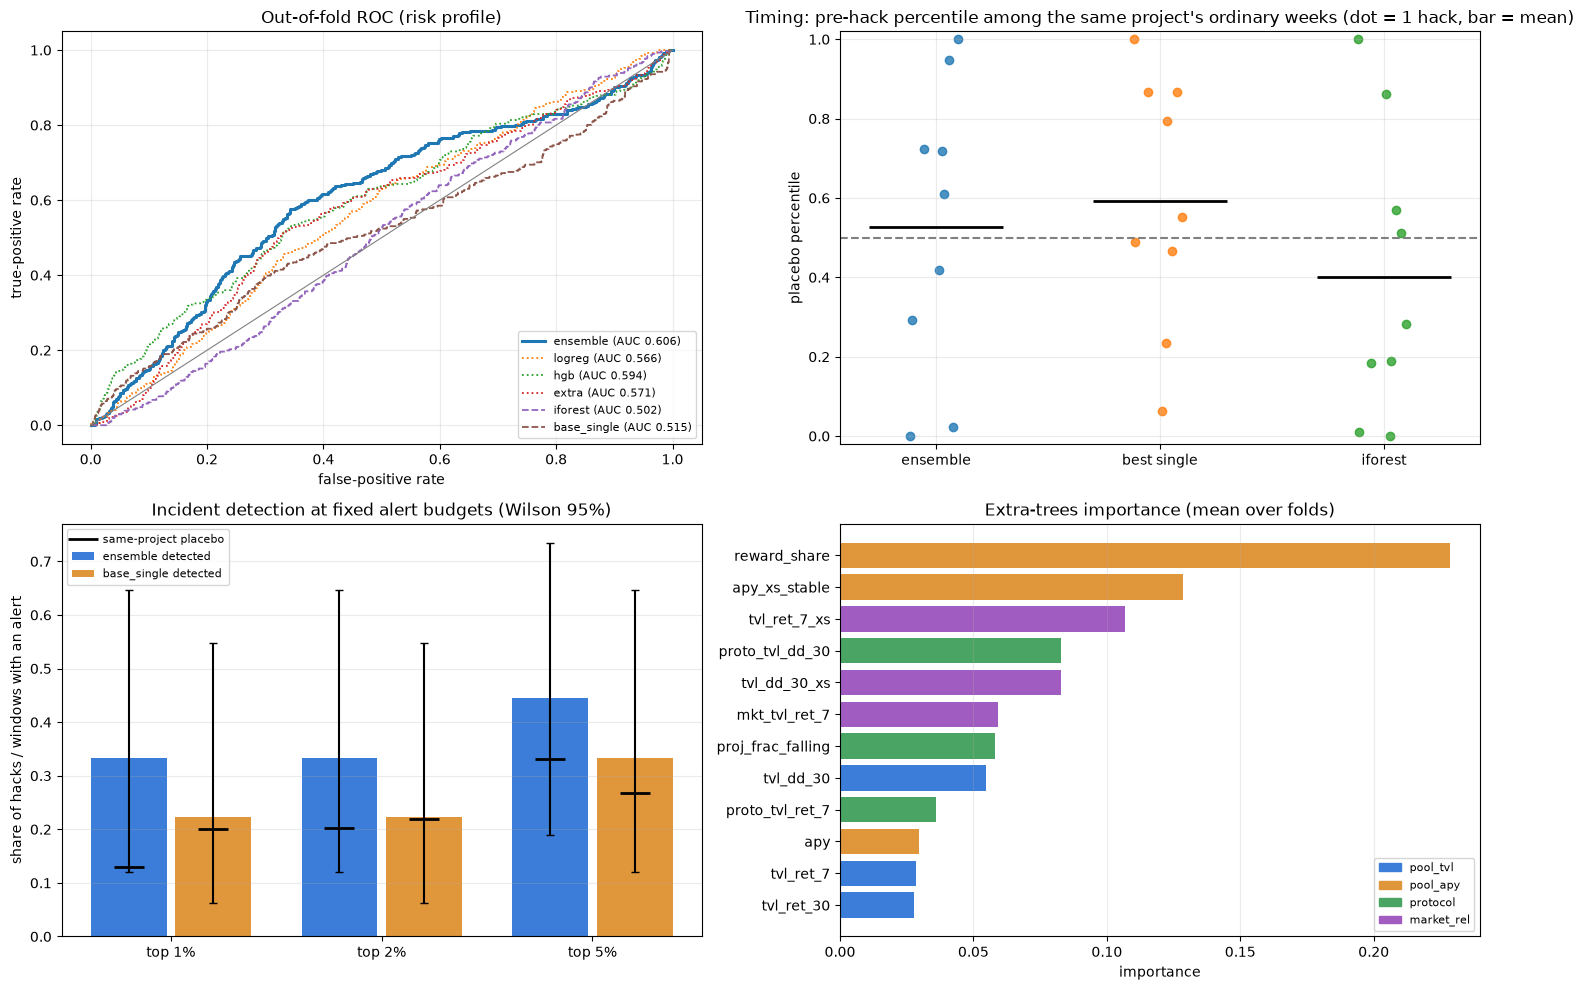

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
e = OOF[~OOF.quarantine]; ye = e.label.values
for c, st in (("ensemble", "-"), ("logreg", ":"), ("hgb", ":"), ("extra", ":"), ("iforest", "--"), ("base_single", "--")):
    if c in e and 0 < ye.sum() < len(ye):
        fpr, tpr, _ = roc_curve(ye, e[c].values); ax[0, 0].plot(fpr, tpr, st, lw=2.2 if c == "ensemble" else 1.3, label=f"{c} (AUC {roc_auc_score(ye, e[c].values):.3f})")
ax[0, 0].plot([0, 1], [0, 1], color="gray", lw=0.8); ax[0, 0].legend(loc="lower right", fontsize=8)
ax[0, 0].set(title="Out-of-fold ROC (risk profile)", xlabel="false-positive rate", ylabel="true-positive rate"); ax[0, 0].grid(alpha=0.25)

t = INC_TBL[INC_TBL.evaluable.astype(bool)] if len(INC_TBL) else INC_TBL
if len(t):
    for j, c in enumerate(["ensemble", "base_single", "iforest"]):
        x = t[f"pct_{c}"].values; ax[0, 1].scatter(np.full(len(x), j) + np.random.default_rng(0).uniform(-0.12, 0.12, len(x)), x, alpha=0.8)
        ax[0, 1].hlines(x.mean(), j - 0.3, j + 0.3, color="k", lw=2)
    ax[0, 1].axhline(0.5, color="gray", ls="--"); ax[0, 1].set_xticks(range(3)); ax[0, 1].set_xticklabels(["ensemble", "best single", "iforest"]); ax[0, 1].set_ylim(-0.02, 1.02)
else:
    ax[0, 1].text(0.5, 0.5, "no evaluable incidents", ha="center", transform=ax[0, 1].transAxes)
ax[0, 1].set(title="Timing: pre-hack percentile among the same project's ordinary weeks (dot = 1 hack, bar = mean)", ylabel="placebo percentile"); ax[0, 1].grid(alpha=0.25)

A2 = ALERTS[ALERTS.score.isin(["ensemble", "base_single"])]; w = 0.2; xs = np.arange(len(CFG.ALERT_BUDGETS))
for j, (c, col) in enumerate((("ensemble", "#3b7dd8"), ("base_single", "#e0963b"))):
    s = A2[A2.score == c].sort_values("budget")
    if s.det_rate.notna().any():
        ax[1, 0].bar(xs + (j - 0.5) * 2 * w, s.det_rate, w * 1.8, yerr=[s.det_rate - s.det_lo, s.det_hi - s.det_rate], capsize=3, color=col, label=f"{c} detected")
        ax[1, 0].plot(xs + (j - 0.5) * 2 * w, s.placebo_rate, "k_", ms=22, mew=2, label="same-project placebo" if j == 0 else None)
ax[1, 0].set_xticks(xs); ax[1, 0].set_xticklabels([f"top {int(q * 100)}%" for q in CFG.ALERT_BUDGETS]); ax[1, 0].legend(fontsize=8)
ax[1, 0].set(title="Incident detection at fixed alert budgets (Wilson 95%)", ylabel="share of hacks / windows with an alert"); ax[1, 0].grid(axis="y", alpha=0.25)

if len(IMPORTANCE):
    top = IMPORTANCE.head(12).iloc[::-1]; pal = dict(zip(GROUPS, ["#3b7dd8", "#e0963b", "#4aa564", "#a05cc0"]))
    ax[1, 1].barh(top.index, top.extra_importance, color=[pal[g] for g in top.group]); ax[1, 1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in pal.values()], labels=list(pal), fontsize=8)
ax[1, 1].set(title="Extra-trees importance (mean over folds)", xlabel="importance"); ax[1, 1].grid(axis="x", alpha=0.25)
if CFG.DATA_SOURCE != "real": fig.suptitle("SYNTHETIC DATA — smoke test only", color="red", fontsize=14)
fig.tight_layout(); fig.savefig(OUT / "summary_figure.png", dpi=150, bbox_inches="tight"); plt.show()

## 14. Tests and controls (run last; the notebook must pass from a clean kernel)
* **Invariants:** no look-ahead in features, positives strictly before events, grouped/embargoed/purged splits, loader round-trip against mock DeFiLlama payloads (no network), deterministic training, metric math.
* **Positive control:** a small synthetic universe with a *planted* precursor — the pipeline **must** find skill (otherwise the ML or the evaluation is broken).
* **Negative control:** the same universe with **no** precursor (hacks still drain pools afterwards) — the pipeline **must not** find skill (otherwise the evaluation manufactures it). Together they show a good or bad real-data result is about the data, not the code.

In [15]:
import tempfile
from unittest import mock

checks = []
def record(name, passed, details=""):
    checks.append(dict(check=name, status="PASS" if bool(passed) else "FAIL", details=str(details)))


# ---------- features / labels ----------
T_cut = int(feat.day_num.quantile(0.6)); h_cut = hist[pd.to_datetime(hist.timestamp, utc=True).dt.floor("D").pipe(to_day_num) <= T_cut]
f_cut = build_features(h_cut, CFG); f_cut = f_cut[f_cut.day_num == T_cut].set_index("pool")[FEATURES]
f_full = feat[feat.day_num == T_cut].set_index("pool")[FEATURES]; common = f_cut.index.intersection(f_full.index)
record("features_have_no_lookahead", len(common) > 10 and np.allclose(f_cut.loc[common].values, f_full.loc[common].values, equal_nan=True, atol=1e-9), f"{len(common)} pools compared at day {T_cut}")
pp = lab[lab.label == 1].merge(incidents[["event_id", "event_day", "detectable"]], left_on="incident_id", right_on="event_id")
record("positives_strictly_before_event_and_detectable_only", bool(len(pp) == 0 or ((pp.day_num < pp.event_day - CFG.LABEL_GAP_DAYS).all() and pp.detectable.all())), f"{len(pp)} positive rows")
record("quarantine_rows_never_positive", not ((lab.quarantine) & (lab.label == 1)).any())
record("purge_covers_label_horizon", CFG.PURGE_DAYS >= CFG.LOOKAHEAD_DAYS + CFG.POST_DAYS)
_mf = pd.DataFrame({"pool": np.repeat(["A", "B"], 61), "project": "P", "day_num": np.tile(np.arange(61), 2),
                    "tvlUsd": np.concatenate([np.where(np.arange(61) >= 40, 1e5, 1e6), np.full(61, 1e6)])})
_mi = pd.DataFrame(dict(project=["P"], event_id=["P|40"], event_day=[40], detectable=[True]))
_ml = label_rows(_mf, _mi, replace(CFG, LABEL_GAP_DAYS=0, POST_DAYS=7, LOOKAHEAD_DAYS=7))
record("pool_level_label_only_victim_pool", set(_ml[_ml.label == 1].pool) == {"A"} and bool(_ml[(_ml.pool == "B") & _ml.day_num.between(33, 39)].quarantine.all()))
record("non_detectable_incident_is_quarantined", int(label_rows(_mf, _mi.assign(detectable=False), CFG).label.sum()) == 0)
record("category_filter", (not categorize("Infrastructure", "Private Key Compromised", CFG)[0]) and categorize("Protocol Logic", "Reentrancy", CFG)[0] and not categorize("", "", CFG)[0])

# ---------- splits ----------
ok_g, ok_emb, ok_cov = True, True, True
for sp in splits[:CFG.CV_FOLDS]:
    te_p, tr_p = set(lab.project[sp["test"]]), set(lab.project[sp["train"]]); ok_g &= not (te_p & tr_p)
    for r in incidents[incidents.project.isin(te_p)].itertuples():
        ok_emb &= not (sp["train"] & lab.day_num.between(r.event_day - CFG.EMBARGO_PRE, r.event_day + CFG.EMBARGO_POST).values).any()
ok_cov = np.all(sum(sp["test"].astype(int) for sp in splits[:CFG.CV_FOLDS]) == 1)
record("grouped_splits_disjoint_projects", ok_g); record("grouped_splits_embargo_applied", ok_emb); record("every_row_tested_exactly_once_per_repeat", ok_cov)
_ws = wf_splits(lab, CFG)
record("walk_forward_train_before_test_with_purge", all(lab.day_num.values[s["train"]].max() + CFG.PURGE_DAYS <= lab.day_num.values[s["test"]].min() for s in _ws) if _ws else True, f"{len(_ws)} folds")
record("oof_rows_unique_pool_day", not OOF.duplicated(["pool", "day_num"]).any())
record("oof_scores_are_percentiles", bool(OOF[SCORE_ORDER].min().min() >= 0 and OOF[SCORE_ORDER].max().max() <= 1))

# ---------- models ----------
_sub = lab[~lab.quarantine].iloc[:60_000]
if _sub.label.sum() > 0:
    _a = predict_all(fit_all(_sub, FEATURES, CFG, ("logreg", "hgb")), _sub.head(300), FEATURES)
    _b = predict_all(fit_all(_sub, FEATURES, CFG, ("logreg", "hgb")), _sub.head(300), FEATURES)
    record("training_is_deterministic", np.allclose(_a.values, _b.values))
_toy = pd.DataFrame({"label": [0] * 200 + [1] * 20, "incident_id": [""] * 200 + ["i"] * 20, "x_good": np.r_[np.random.default_rng(1).normal(0, 1, 200), np.random.default_rng(2).normal(2, 1, 20)],
                     "x_bad": np.random.default_rng(3).normal(0, 1, 220)})
_toy["x_neg"] = -_toy.x_good
_s, _w = make_train_set(_toy, replace(CFG, INCIDENT_WEIGHT_FRAC=0.1))
record("best_single_finds_signal_and_sign", best_single(_s, ["x_bad", "x_neg"], _w) == ("x_neg", -1.0) or best_single(_s, ["x_bad", "x_good"], _w)[0] == "x_good")
record("incident_weights_equalise_incidents", abs(_w[_s.label.values == 1].sum() - 200 * 0.1) < 1e-6)

# ---------- metric math ----------
_w1 = wilson(0, 10); record("wilson_bounds", _w1[0] == 0 and 0.2 < _w1[1] < 0.3)
_n = 120; _cfgT = replace(CFG, LOOKAHEAD_DAYS=7, LABEL_GAP_DAYS=0, COOLDOWN_DAYS=5, MIN_PLACEBO_WINDOWS=10)
_o = pd.DataFrame({"project": "p", "day_num": np.arange(_n), "label": 0, "quarantine": False}); _o["s"] = np.random.default_rng(0).uniform(0, 0.5, _n)
_o.loc[_o.day_num.between(90, 96), "s"] = 0.99                                      # score spikes in the 7 days before the event at day 97
_ie = pd.DataFrame(dict(project=["p"], event_id=["p|97"], event_day=[97], detectable=[True]))
_tb, _pl = incident_scores(_o, ["s"], _ie, _ie, _cfgT)
record("incident_percentile_is_1_when_score_peaks_before_hack", bool(_tb.evaluable.iloc[0]) and _tb.pct_s.iloc[0] > 0.98, f"pct={_tb.pct_s.iloc[0]:.3f}")
record("placebo_windows_only_from_earlier_non_overlapping_history", bool(0 < len(_pl[("p|97", "s")]) <= 90), f"{len(_pl[('p|97', 's')])} placebo windows")
# regression test for the regime bias found while building v4: a drained project after the hack must NOT be used as 'ordinary' weeks
_n2 = 300; _o2 = pd.DataFrame({"project": "p", "day_num": np.arange(_n2), "label": 0, "quarantine": False}); _o2["s"] = np.random.default_rng(1).uniform(0.4, 0.6, _n2)
_o2.loc[_o2.day_num >= 200, "s"] = 0.0                                              # project is dead after the hack at day 200
_ie2 = pd.DataFrame(dict(project=["p"], event_id=["p|200"], event_day=[200], detectable=[True]))
_tb2, _pl2 = incident_scores(_o2, ["s"], _ie2, _ie2, _cfgT)
record("post_hack_dead_regime_never_used_as_placebo", bool(_tb2.evaluable.iloc[0]) and _pl2[("p|200", "s")].min() > 0.3, f"min placebo score {_pl2[('p|200', 's')].min():.2f}")
_o3 = _o.copy(); _o3["s"] = np.random.default_rng(0).uniform(0, 0.5, _n); _o3.loc[_o3.day_num.between(95, 96), "s"] = 0.99   # spike only in the last 2 days before the event
_g0 = incident_scores(_o3, ["s"], _ie, _ie, _cfgT)[0].pct_s.iloc[0]; _g3 = incident_scores(_o3, ["s"], _ie, _ie, replace(_cfgT, LABEL_GAP_DAYS=3))[0].pct_s.iloc[0]
record("label_gap_moves_the_evaluated_window_off_the_last_days", _g0 > 0.98 and _g3 < 0.98, f"pct gap0={_g0:.3f}, gap3={_g3:.3f}")

# ---------- data layer round-trip on mock DeFiLlama payloads (no network) ----------
class _Resp:
    def __init__(self, body): self._b = json.loads(json.dumps(body))
    def raise_for_status(self): pass
    def json(self): return self._b


def _mock_payloads(cfg_s):
    h, hk = make_synthetic(cfg_s); h, _ = clean_history(h, cfg_s); projs = sorted(h.project.unique()); ids = {p: str(1000 + i) for i, p in enumerate(projs)}
    hk = [dict(x) for x in hk]; first = next(x for x in hk if x["name"].startswith("Proto"))
    hacked_proj = normalize_name(first["name"]); hp = next(p for p in projs if normalize_name(p) == hacked_proj)
    first["name"], first["defillamaId"] = "Totally Different Brand", ids[hp]                       # only the id join can recover this one
    pools = h.groupby("pool").agg(project=("project", "first"), symbol=("symbol", "first"), tvlUsd=("tvlUsd", "last")).reset_index()
    charts = {}
    for pool, g in h.groupby("pool"):
        charts[pool] = [dict(timestamp=(t + pd.Timedelta(hours=23, minutes=1)).strftime("%Y-%m-%dT%H:%M:%S.000Z"), tvlUsd=float(a), apy=float(b),
                             apyBase=None if np.isnan(c) else float(c), apyReward=float(d)) for t, a, b, c, d in zip(g.timestamp, g.tvlUsd, g.apy, g.apyBase, g.apyReward)]
    return h, hk, [dict(id=ids[p], slug=p, name=p) for p in projs], pools, charts, hp


class _MockAPI:
    def __init__(self, hk, protocols, pools, charts): self.hk, self.pr, self.pools, self.charts, self.calls = hk, protocols, pools, charts, []
    def get(self, url, headers=None, timeout=None):
        from urllib.parse import unquote
        self.calls.append(url)
        if url == "https://api.llama.fi/hacks": return _Resp(self.hk)
        if url == "https://api.llama.fi/protocols": return _Resp(self.pr)
        if url == "https://yields.llama.fi/pools": return _Resp(dict(status="success", data=self.pools.to_dict("records")))
        if url.startswith("https://yields.llama.fi/chart/"): return _Resp(dict(status="success", data=self.charts[unquote(url.split("/chart/", 1)[1])]))
        raise AssertionError(url)


_cs = replace(CFG, DATA_SOURCE="synthetic", SYN_PROJECTS=14, SYN_DAYS=200, SYN_INCIDENTS=4, SEED=11, MIN_POOLS_PER_DAY=5, STABLE_MIN_TVL=1.0)
_h, _hk, _pr, _pools, _charts, _hp = _mock_payloads(_cs)
with tempfile.TemporaryDirectory() as tmp, tempfile.TemporaryDirectory() as tmp2:
    api = _MockAPI(_hk, _pr, _pools, _charts)
    rc = replace(_cs, DATA_SOURCE="real", ARTIFACT_DIR=tmp, ALLOW_NETWORK=True, MAX_POOLS=len(_pools), REQUEST_DELAY=0.0, MAX_REQUESTS=500, MIN_TVL_FETCH=1.0)
    with mock.patch("requests.get", api.get):
        fetch_cache(rc); n1 = len(api.calls); fetch_cache(replace(rc, ALLOW_NETWORK=False))
        record("fetch_cache_rerun_uses_cache_only", len(api.calls) == n1)
        try: fetch_cache(replace(rc, ALLOW_NETWORK=False, ARTIFACT_DIR=tmp2)); _refuse = False
        except RuntimeError: _refuse = True
        record("fetch_cache_offline_cold_cache_refuses", _refuse)
        n_before = len(api.calls); fetch_cache(replace(rc, ARTIFACT_DIR=tempfile.mkdtemp(), MAX_REQUESTS=5))
        record("fetch_cache_request_budget_enforced", len(api.calls) - n_before <= 5)
    lh, lhk = load_cache(replace(rc, ALLOW_NETWORK=False)); lh, _ = clean_history(lh, rc)
    record("load_cache_roundtrip_matches_source", len(lh) == len(_h) and np.allclose(np.sort(lh.apy.values), np.sort(_h.apy.values)), f"{len(lh)} rows")
    _lf = prepare_features(lh, _cs); _inc = match_incidents(lhk, _lf, _cs)
    record("id_join_recovers_renamed_hack", "defillama id" in set(_inc.match_method) and _hp in set(_inc.project), _inc.match_method.value_counts().to_dict())
try: load_cache(replace(CFG, ARTIFACT_DIR=tempfile.mkdtemp(), ALLOW_NETWORK=False)); _fnf = False
except FileNotFoundError: _fnf = True
record("load_cache_without_cache_fails_loudly", _fnf)


# ---------- positive / negative controls (the evaluation must find skill when it exists and invent none when it does not) ----------
def evaluate_universe(cfg_s: Config) -> dict:
    h, hk = make_synthetic(cfg_s); h, _ = clean_history(h, cfg_s); f = prepare_features(h, cfg_s)
    inc = match_incidents(hk, f, cfg_s); lb = label_rows(f, inc, cfg_s)
    o, _, _ = run_cv(lb, group_splits(lb, inc, cfg_s, cfg_s.SEED), FEATURES, cfg_s, learn=("logreg", "hgb"), verbose=False)
    rw = row_metrics(o, cfg_s, cols=["ensemble", "base_single"]); ie = eval_incident_sets(o, inc, lb, cfg_s)
    tb, _ = incident_scores(o, ["ensemble"], ie, inc, cfg_s); sm = incident_summary(tb, ["ensemble"], cfg_s)
    return dict(rows=rw.set_index("score").loc["ensemble"], inc=sm.iloc[0], n_inc=int(lb.loc[lb.label == 1, "incident_id"].nunique()))


if CFG.RUN_CONTROLS:
    base_ctl = replace(CFG, DATA_SOURCE="synthetic", SYN_PROJECTS=40, SYN_DAYS=500, SYN_INCIDENTS=18, CV_REPEATS=1, BOOT=60, BOOT_INC=1000, NEG_CAP=30_000, SEED=7, MIN_POOLS_PER_DAY=30)
    pos_c, neg_c = evaluate_universe(replace(base_ctl, SYN_PRECURSOR=1.0)), evaluate_universe(replace(base_ctl, SYN_PRECURSOR=0.0))
    ctl = pd.DataFrame([dict(control="positive (precursor planted)", incidents_with_positives=pos_c["n_inc"], roc_auc=pos_c["rows"].roc_auc, roc_lo=pos_c["rows"].roc_lo, placebo_pct=pos_c["inc"].mean_placebo_pct, pct_ci_lo=pos_c["inc"].ci_lo),
                        dict(control="negative (no precursor)", incidents_with_positives=neg_c["n_inc"], roc_auc=neg_c["rows"].roc_auc, roc_lo=neg_c["rows"].roc_lo, placebo_pct=neg_c["inc"].mean_placebo_pct, pct_ci_lo=neg_c["inc"].ci_lo)])
    display(ctl.round(3))
    record("positive_control_finds_risk_profile_skill", pos_c["rows"].roc_auc > 0.65 and pos_c["rows"].roc_lo > 0.5, f"AUC {pos_c['rows'].roc_auc:.3f}")
    record("positive_control_finds_timing_skill", pos_c["inc"].mean_placebo_pct > 0.65 and pos_c["inc"].ci_lo > 0.5, f"placebo pct {pos_c['inc'].mean_placebo_pct:.3f}")
    record("negative_control_invents_no_timing_skill", neg_c["inc"].mean_placebo_pct < 0.65 and neg_c["inc"].ci_lo < 0.6, f"placebo pct {neg_c['inc'].mean_placebo_pct:.3f}")
    record("negative_control_invents_no_risk_profile_skill", neg_c["rows"].roc_auc < 0.65, f"AUC {neg_c['rows'].roc_auc:.3f}")

quality = pd.DataFrame(checks); display(quality); quality.to_csv(OUT / "quality_report.csv", index=False)
failed = quality[quality.status == "FAIL"]
print(f"{len(quality) - len(failed)}/{len(quality)} checks passed")
assert failed.empty, "Failures: " + ", ".join(failed.check)

fetch_cache: live requests=52, charts on disk=49
fetch_cache: live requests=0, charts on disk=49
WARNING - PARTIAL CACHE: MAX_REQUESTS=5 reached; cache kept, rerun to resume.
fetch_cache: live requests=5, charts on disk=2
cache: 49 pools, 29 hack-feed events, chart files without catalogue entry: 0


,control,incidents_with_positives,roc_auc,roc_lo,placebo_pct,pct_ci_lo
0,positive (precursor planted),18,0.720,0.654,0.803,0.671
1,negative (no precursor),18,0.524,0.423,0.493,0.341


,check,status,details
0,features_have_no_lookahead,PASS,217 pools compared at day 20477
1,positives_strictly_before_event_and_detectable...,PASS,311 positive rows
2,quarantine_rows_never_positive,PASS,
3,purge_covers_label_horizon,PASS,
4,pool_level_label_only_victim_pool,PASS,
5,non_detectable_incident_is_quarantined,PASS,
6,category_filter,PASS,
7,grouped_splits_disjoint_projects,PASS,
8,grouped_splits_embargo_applied,PASS,
9,every_row_tested_exactly_once_per_repeat,PASS,


31/31 checks passed


## 15. What this notebook can and cannot support

**Allowed regardless of outcome:** a leakage-safe, reproducible, tested pipeline; an ML risk model whose out-of-fold performance is measured against honest baselines; and the positive/negative controls showing the evaluation behaves.

**Allowed claim of predictive skill only if** §11 prints *SKILL*, the walk-forward stress test and the label-gap check do not contradict it, and the number of evaluable incidents is large enough for the intervals to be informative. *RISK-PROFILE ONLY* supports "the model ranks which pools are more likely to be hit", not "the model warns before a hack".

**Known limits (state them in any write-up):** very few incidents have an observable TVL footprint, so intervals are wide whatever the model does; positives are chosen using post-event TVL, so recall is measured on *observable* hacks only, not all hacks; the pool catalogue only lists currently-listed pools (survivorship; mitigated by force-including hacked projects); the grouped CV may train on incidents that happened after the test incident (use the walk-forward line for the past-only view); DeFiLlama hack dates and classifications are imperfect; reported APY is not realised yield; regimes change between 2022 and 2026.

**Reproduce:** keep `artifacts/raw` from the feasibility run, leave `ALLOW_NETWORK=False`, *Restart & Run All*. All numbers are written to `artifacts/v4/` (`row_metrics.csv`, `incident_summary.csv`, `alert_budgets.csv`, `robustness.csv`, `run_manifest.json`).